In [67]:
# ============================================================
# Experiment 2A — Step 1
# Load Experiment 1 plans and reconstruct reuse boundaries
# ============================================================

from pathlib import Path
import ast
import itertools

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

EXP1_DIR = Path("./experiment1_results")

PLAN_SUMMARY_FILE = (
    EXP1_DIR / "experiment1_plan_summary.csv"
)

assert PLAN_SUMMARY_FILE.exists(), (
    f"Missing file: {PLAN_SUMMARY_FILE.resolve()}"
)


# ------------------------------------------------------------
# Load Experiment 1 plan-level results
# ------------------------------------------------------------

plans = pd.read_csv(PLAN_SUMMARY_FILE)

print("Loaded plans:", len(plans))
print("Circuits:", plans["circuit"].nunique())

display(
    plans[
        [
            "circuit",
            "plan_id",
            "gidnet_seed",
            "plan_signature",
            "width",
            "normalized_logical_depth",
            "mean_swaps",
            "mean_routed_depth",
        ]
    ].head()
)


# ------------------------------------------------------------
# Parse the canonical GidNET plan signature
#
# Example:
# ((0, 11), (1,), (2, 4, 6), ...)
# ------------------------------------------------------------

def parse_plan_signature(signature):
    if isinstance(signature, str):
        signature = ast.literal_eval(signature)

    return tuple(
        tuple(int(q) for q in chain)
        for chain in signature
    )


def extract_reuse_boundaries(chains):
    """
    For:
        (q0, q5, q9)

    return:
        (q0, q5)
        (q5, q9)
    """

    boundaries = []

    for chain in chains:
        for i in range(len(chain) - 1):
            boundaries.append(
                (chain[i], chain[i + 1])
            )

    return tuple(boundaries)


plans["reuse_chains"] = (
    plans["plan_signature"]
    .apply(parse_plan_signature)
)

plans["reuse_boundaries"] = (
    plans["reuse_chains"]
    .apply(extract_reuse_boundaries)
)

plans["num_reuse_boundaries"] = (
    plans["reuse_boundaries"]
    .apply(len)
)


# ------------------------------------------------------------
# Sanity checks
#
# For N original logical qubits compressed to width W:
#
# number of reuse boundaries = N - W
#
# We do not yet have N directly in this table, so for now
# verify that every plan of the same circuit has the same
# number of boundaries.
# ------------------------------------------------------------

boundary_check = (
    plans
    .groupby("circuit")
    ["num_reuse_boundaries"]
    .agg(["min", "max", "nunique"])
)

print("\nReuse-boundary counts:")
display(boundary_check)

assert (
    boundary_check["nunique"] == 1
).all()

print("Boundary-count consistency check passed.")

Loaded plans: 50
Circuits: 5


,circuit,plan_id,gidnet_seed,plan_signature,width,normalized_logical_depth,mean_swaps,mean_routed_depth
0,system9.qasm,P0,0,"((0, 11), (1,), (2, 4, 6), (3, 7, 8), (5,), (9...",7,173,88.2,294.6
1,system9.qasm,P1,1,"((0, 5, 7), (1,), (2, 4, 6, 8), (3,), (9,), (1...",7,176,94.2,306.2
2,system9.qasm,P10,16,"((0, 3), (1,), (2, 4, 6), (5, 7, 8), (9,), (10...",7,174,87.2,296.6
3,system9.qasm,P11,17,"((0, 10), (1, 7), (2, 5), (3,), (4, 6, 8), (9,...",7,168,91.2,288.4
4,system9.qasm,P12,18,"((0, 10), (1,), (2, 4, 6, 8), (3, 7), (5,), (9...",7,178,88.8,298.4



Reuse-boundary counts:


,min,max,nunique
circuit,,,
alu-bdd_288.qasm,2,2,1
mini_alu_305.qasm,4,4,1
rd73_140.qasm,5,5,1
sym9_146.qasm,7,7,1
system9.qasm,5,5,1


Boundary-count consistency check passed.


In [68]:
# ============================================================
# Experiment 2A — Step 2
# BEST / MEDIAN / WORST plans
# ============================================================


def plan_number(plan_id):
    return int(str(plan_id).replace("P", ""))


selected_rows = []


for circuit_name, df in plans.groupby("circuit"):

    df = df.copy()

    df["plan_number"] = (
        df["plan_id"]
        .map(plan_number)
    )

    # Sort primarily by physical SWAP cost
    ordered = (
        df
        .sort_values(
            ["mean_swaps", "plan_number"]
        )
        .reset_index(drop=True)
    )

    best = ordered.iloc[0]
    median = ordered.iloc[len(ordered) // 2]
    worst = ordered.iloc[-1]

    for role, row in [
        ("BEST", best),
        ("MEDIAN", median),
        ("WORST", worst),
    ]:

        selected_rows.append({
            "circuit": circuit_name,
            "role": role,
            "plan_id": row["plan_id"],
            "gidnet_seed": int(
                row["gidnet_seed"]
            ),
            "width": int(row["width"]),
            "normalized_logical_depth":
                int(
                    row[
                        "normalized_logical_depth"
                    ]
                ),
            "mean_swaps":
                row["mean_swaps"],
            "mean_routed_depth":
                row["mean_routed_depth"],
            "num_reuse_boundaries":
                row[
                    "num_reuse_boundaries"
                ],
        })


selected_plans = pd.DataFrame(
    selected_rows
)

display(selected_plans)

,circuit,role,plan_id,gidnet_seed,width,normalized_logical_depth,mean_swaps,mean_routed_depth,num_reuse_boundaries
0,alu-bdd_288.qasm,BEST,P2,2,5,52,21.0,79.0,2
1,alu-bdd_288.qasm,MEDIAN,P3,5,5,50,21.6,78.0,2
2,alu-bdd_288.qasm,WORST,P1,1,5,50,23.2,79.6,2
3,mini_alu_305.qasm,BEST,P2,2,6,94,41.6,156.0,4
4,mini_alu_305.qasm,MEDIAN,P3,3,6,103,44.4,157.4,4
5,mini_alu_305.qasm,WORST,P9,10,6,98,46.8,163.2,4
6,rd73_140.qasm,BEST,P3,9,5,142,51.4,215.8,5
7,rd73_140.qasm,MEDIAN,P1,2,5,142,53.6,219.6,5
8,rd73_140.qasm,WORST,P2,5,5,142,61.6,226.4,5
9,sym9_146.qasm,BEST,P1,1,5,199,75.4,304.8,7


In [69]:
# ============================================================
# Experiment 2A — Step 2b
# Find strongest logical-depth-matched pair
#
# Requirement:
# relative logical-depth difference <= 5%
#
# Among valid pairs, select the pair having the
# largest mean-SWAP difference.
# ============================================================

DEPTH_MATCH_THRESHOLD = 0.05

depth_matched_rows = []


for circuit_name, df in plans.groupby("circuit"):

    candidates = []

    rows = list(df.iterrows())

    for (_, a), (_, b) in itertools.combinations(
        rows,
        2
    ):

        da = float(
            a["normalized_logical_depth"]
        )

        db = float(
            b["normalized_logical_depth"]
        )

        relative_depth_difference = (
            abs(da - db) / min(da, db)
        )

        if (
            relative_depth_difference
            > DEPTH_MATCH_THRESHOLD
        ):
            continue

        swap_difference = abs(
            float(a["mean_swaps"])
            - float(b["mean_swaps"])
        )

        # Define better/worse using physical SWAP cost
        if a["mean_swaps"] <= b["mean_swaps"]:
            better = a
            worse = b
        else:
            better = b
            worse = a

        candidates.append({
            "circuit": circuit_name,

            "better_plan":
                better["plan_id"],
            "better_gidnet_seed":
                int(better["gidnet_seed"]),
            "better_logical_depth":
                int(
                    better[
                        "normalized_logical_depth"
                    ]
                ),
            "better_mean_swaps":
                better["mean_swaps"],

            "worse_plan":
                worse["plan_id"],
            "worse_gidnet_seed":
                int(worse["gidnet_seed"]),
            "worse_logical_depth":
                int(
                    worse[
                        "normalized_logical_depth"
                    ]
                ),
            "worse_mean_swaps":
                worse["mean_swaps"],

            "relative_depth_difference":
                relative_depth_difference,

            "relative_depth_difference_pct":
                100
                * relative_depth_difference,

            "swap_difference":
                swap_difference,
        })

    if not candidates:
        raise RuntimeError(
            f"No depth-matched pair found "
            f"for {circuit_name}"
        )

    candidate_df = pd.DataFrame(
        candidates
    )

    # Largest physical-cost difference first.
    # If tied, prefer closer logical depth.
    best_pair = (
        candidate_df
        .sort_values(
            [
                "swap_difference",
                "relative_depth_difference",
            ],
            ascending=[False, True]
        )
        .iloc[0]
    )

    depth_matched_rows.append(
        best_pair.to_dict()
    )


depth_matched_pairs = pd.DataFrame(
    depth_matched_rows
)

display(
    depth_matched_pairs[
        [
            "circuit",

            "better_plan",
            "better_logical_depth",
            "better_mean_swaps",

            "worse_plan",
            "worse_logical_depth",
            "worse_mean_swaps",

            "relative_depth_difference_pct",
            "swap_difference",
        ]
    ]
)

,circuit,better_plan,better_logical_depth,better_mean_swaps,worse_plan,worse_logical_depth,worse_mean_swaps,relative_depth_difference_pct,swap_difference
0,alu-bdd_288.qasm,P2,52,21.0,P1,50,23.2,4.000000,2.2
1,mini_alu_305.qasm,P2,94,41.6,P9,98,46.8,4.255319,5.2
2,rd73_140.qasm,P3,142,51.4,P2,142,61.6,0.000000,10.2
3,sym9_146.qasm,P1,199,75.4,P5,197,90.0,1.015228,14.6
4,system9.qasm,P7,177,86.0,P8,177,98.2,0.000000,12.2


In [70]:
# ============================================================
# Experiment 2A — Step 2c
# Human-readable plan dump + structural diff
# ============================================================


def get_plan(circuit_name, plan_id):

    match = plans[
        (plans["circuit"] == circuit_name)
        &
        (plans["plan_id"] == plan_id)
    ]

    if len(match) != 1:
        raise ValueError(
            f"Expected exactly one row for "
            f"{circuit_name} / {plan_id}, "
            f"found {len(match)}"
        )

    return match.iloc[0]


def print_plan(row):

    print(
        f"{row['circuit']} — "
        f"{row['plan_id']}"
    )

    print(
        f"GidNET seed: "
        f"{row['gidnet_seed']}"
    )

    print(
        f"Width: {row['width']}"
    )

    print(
        "Normalized logical depth:",
        row["normalized_logical_depth"]
    )

    print(
        "Mean SWAP:",
        row["mean_swaps"]
    )

    print("\nReuse chains:")

    for i, chain in enumerate(
        row["reuse_chains"]
    ):

        chain_text = " -> ".join(
            f"q{q}"
            for q in chain
        )

        print(
            f"  Chain {i}: "
            f"{chain_text}"
        )

    print("\nReuse boundaries:")

    for a, b in row[
        "reuse_boundaries"
    ]:

        print(
            f"  q{a} -> q{b}"
        )


def compare_plans(
    circuit_name,
    better_plan,
    worse_plan
):

    better = get_plan(
        circuit_name,
        better_plan
    )

    worse = get_plan(
        circuit_name,
        worse_plan
    )

    better_edges = set(
        better["reuse_boundaries"]
    )

    worse_edges = set(
        worse["reuse_boundaries"]
    )

    common = sorted(
        better_edges & worse_edges
    )

    better_only = sorted(
        better_edges - worse_edges
    )

    worse_only = sorted(
        worse_edges - better_edges
    )

    print("=" * 70)
    print(circuit_name)
    print("=" * 70)

    print("\nBETTER PLAN")
    print_plan(better)

    print("\nWORSE PLAN")
    print_plan(worse)

    print("\n--- STRUCTURAL DIFF ---")

    print("\nCommon boundaries:")
    for a, b in common:
        print(f"  q{a} -> q{b}")

    print("\nBetter-only boundaries:")
    for a, b in better_only:
        print(f"  q{a} -> q{b}")

    print("\nWorse-only boundaries:")
    for a, b in worse_only:
        print(f"  q{a} -> q{b}")

    return {
        "common": common,
        "better_only": better_only,
        "worse_only": worse_only,
    }


plan_diffs = {}

for _, pair in depth_matched_pairs.iterrows():

    circuit_name = pair["circuit"]

    plan_diffs[circuit_name] = (
        compare_plans(
            circuit_name,
            pair["better_plan"],
            pair["worse_plan"],
        )
    )

    print("\n\n")

alu-bdd_288.qasm

BETTER PLAN
alu-bdd_288.qasm — P2
GidNET seed: 2
Width: 5
Normalized logical depth: 52
Mean SWAP: 21.0

Reuse chains:
  Chain 0: q0 -> q4
  Chain 1: q1 -> q6
  Chain 2: q2
  Chain 3: q3
  Chain 4: q5

Reuse boundaries:
  q0 -> q4
  q1 -> q6

WORSE PLAN
alu-bdd_288.qasm — P1
GidNET seed: 1
Width: 5
Normalized logical depth: 50
Mean SWAP: 23.2

Reuse chains:
  Chain 0: q0
  Chain 1: q1 -> q2 -> q4
  Chain 2: q3
  Chain 3: q5
  Chain 4: q6

Reuse boundaries:
  q1 -> q2
  q2 -> q4

--- STRUCTURAL DIFF ---

Common boundaries:

Better-only boundaries:
  q0 -> q4
  q1 -> q6

Worse-only boundaries:
  q1 -> q2
  q2 -> q4



mini_alu_305.qasm

BETTER PLAN
mini_alu_305.qasm — P2
GidNET seed: 2
Width: 6
Normalized logical depth: 94
Mean SWAP: 41.6

Reuse chains:
  Chain 0: q1 -> q5 -> q9
  Chain 1: q2 -> q8
  Chain 2: q3
  Chain 3: q4
  Chain 4: q6
  Chain 5: q7 -> q0

Reuse boundaries:
  q1 -> q5
  q5 -> q9
  q2 -> q8
  q7 -> q0

WORSE PLAN
mini_alu_305.qasm — P9
GidNET seed: 10

In [71]:
# ============================================================
# Experiment 2A — Step 3
# Load the exact logical circuits seen by GidNET
# ============================================================

from pathlib import Path
from qiskit import QuantumCircuit


# EXACT benchmark directory used in Experiment 1
BENCHMARK_DIR = Path(
    r"C:\Users\ASUS\Documents\Quantum computing\Qiskit\CaQR-main\CaQR-main\benchmarks"
)

assert BENCHMARK_DIR.exists(), (
    f"Benchmark directory not found: {BENCHMARK_DIR}"
)


# ------------------------------------------------------------
# Same preprocessing used in Experiment 1
# ------------------------------------------------------------

def prepare_gidnet_input(qc):
    """
    Exact logical preprocessing used before GidNET.

    - Reject classical operations/conditions
    - Remove unused classical registers
    - Remove idle qubits
    - Preserve operation order
    """

    # Ensure purely quantum benchmark
    for item in qc.data:
        op = item.operation

        if len(item.clbits) > 0:
            raise ValueError(
                f"Circuit contains classical operands: {op.name}"
            )

        if getattr(op, "condition", None) is not None:
            raise ValueError(
                f"Circuit contains conditional operation: {op.name}"
            )

    # Find active qubits
    active_qubits = sorted({
        qc.find_bit(q).index
        for item in qc.data
        for q in item.qubits
    })

    idle_qubits = sorted(
        set(range(qc.num_qubits))
        - set(active_qubits)
    )

    old_to_new = {
        old_idx: new_idx
        for new_idx, old_idx
        in enumerate(active_qubits)
    }

    # Rebuild compact quantum-only circuit
    compact = QuantumCircuit(
        len(active_qubits)
    )

    for item in qc.data:

        op = item.operation

        new_qargs = [
            old_to_new[
                qc.find_bit(q).index
            ]
            for q in item.qubits
        ]

        compact.append(
            op.copy(),
            new_qargs,
            []
        )

    metadata = {
        "original_declared_qubits":
            qc.num_qubits,

        "active_qubits":
            len(active_qubits),

        "idle_qubits":
            idle_qubits,

        "old_to_new":
            old_to_new,
    }

    return compact, metadata


# ------------------------------------------------------------
# Load all five circuits
# ------------------------------------------------------------

logical_circuits = {}
preprocessing_info = {}

for circuit_name in sorted(
    plans["circuit"].unique()
):

    path = BENCHMARK_DIR / circuit_name

    assert path.exists(), (
        f"Missing benchmark: {path}"
    )

    qc_original = (
        QuantumCircuit.from_qasm_file(path)
    )

    qc_compact, info = (
        prepare_gidnet_input(qc_original)
    )

    logical_circuits[circuit_name] = (
        qc_compact
    )

    preprocessing_info[circuit_name] = info

    print(
        f"{circuit_name}: "
        f"declared={qc_original.num_qubits}, "
        f"active={qc_compact.num_qubits}, "
        f"idle={len(info['idle_qubits'])}"
    )

alu-bdd_288.qasm: declared=16, active=7, idle=9
mini_alu_305.qasm: declared=16, active=10, idle=6
rd73_140.qasm: declared=16, active=10, idle=6
sym9_146.qasm: declared=16, active=12, idle=4
system9.qasm: declared=16, active=12, idle=4


In [72]:
# ============================================================
# Experiment 2A — Step 3b
# Extract temporal 2Q interaction context
# ============================================================

from collections import defaultdict


def build_interaction_profiles(qc):
    """
    Build temporal two-qubit interaction profiles.

    For every logical qubit q, stores interactions in
    original circuit order:

        q -> partner

    Each event preserves:
        - operation index
        - approximate logical layer
        - gate name
        - partner
    """

    profiles = defaultdict(list)

    # Track first logical activity of each qubit
    first_activity_op = {}
    first_activity_layer = {}

    # Number of operations involving each qubit
    local_op_count = defaultdict(int)

    # First 2Q information
    first_2q_local_delay = {}
    first_2q_op_index = {}
    first_2q_layer = {}

    # Simple ASAP logical-layer assignment
    last_layer = defaultdict(lambda: -1)

    for op_index, item in enumerate(qc.data):

        op = item.operation

        if op.name == "barrier":
            continue

        qindices = [
            qc.find_bit(q).index
            for q in item.qubits
        ]

        if len(qindices) == 0:
            continue

        layer = (
            max(
                last_layer[q]
                for q in qindices
            )
            + 1
        )

        for q in qindices:
            last_layer[q] = layer

            if q not in first_activity_op:
                first_activity_op[q] = op_index
                first_activity_layer[q] = layer

        # Exactly two-qubit interaction
        if len(qindices) == 2:

            qa, qb = qindices

            # First 2Q interaction delay for qa
            if qa not in first_2q_local_delay:
                first_2q_local_delay[qa] = (
                    local_op_count[qa]
                )
                first_2q_op_index[qa] = op_index
                first_2q_layer[qa] = layer

            # First 2Q interaction delay for qb
            if qb not in first_2q_local_delay:
                first_2q_local_delay[qb] = (
                    local_op_count[qb]
                )
                first_2q_op_index[qb] = op_index
                first_2q_layer[qb] = layer

            profiles[qa].append({
                "partner": qb,
                "gate": op.name,
                "op_index": op_index,
                "layer": layer,
            })

            profiles[qb].append({
                "partner": qa,
                "gate": op.name,
                "op_index": op_index,
                "layer": layer,
            })

        # Increment local operation count AFTER
        # processing current operation.
        for q in qindices:
            local_op_count[q] += 1

    metadata = {}

    for q in range(qc.num_qubits):

        if q in first_2q_layer:
            layer_delay = (
                first_2q_layer[q]
                - first_activity_layer[q]
            )
        else:
            layer_delay = None

        metadata[q] = {
            "first_activity_op":
                first_activity_op.get(q),

            "first_activity_layer":
                first_activity_layer.get(q),

            "first_2q_op":
                first_2q_op_index.get(q),

            "first_2q_layer":
                first_2q_layer.get(q),

            "first_2q_local_op_delay":
                first_2q_local_delay.get(q),

            "first_2q_layer_delay":
                layer_delay,
        }

    return profiles, metadata


interaction_profiles = {}
qubit_timing = {}


for circuit_name, qc in (
    logical_circuits.items()
):

    profiles, timing = (
        build_interaction_profiles(qc)
    )

    interaction_profiles[
        circuit_name
    ] = profiles

    qubit_timing[
        circuit_name
    ] = timing


print("Interaction profiles built.")

Interaction profiles built.


In [73]:
# ============================================================
# Experiment 2A — Step 3c
# Inspect changed reuse boundaries
# ============================================================

K = 5


def boundary_context(
    circuit_name,
    predecessor,
    successor,
    k=5
):

    profiles = (
        interaction_profiles[
            circuit_name
        ]
    )

    timing = (
        qubit_timing[
            circuit_name
        ]
    )

    pred_events = list(
        profiles[predecessor]
    )

    succ_events = list(
        profiles[successor]
    )

    # Last k interactions of predecessor
    tail_events = pred_events[-k:]

    # First k interactions of successor
    head_events = succ_events[:k]

    tail_sequence = [
        e["partner"]
        for e in tail_events
    ]

    head_sequence = [
        e["partner"]
        for e in head_events
    ]

    return {
        "tail_sequence":
            tail_sequence,

        "head_sequence":
            head_sequence,

        "tail_set":
            set(tail_sequence),

        "head_set":
            set(head_sequence),

        "tail_events":
            tail_events,

        "head_events":
            head_events,

        "successor_first_2q_local_delay":
            timing[successor][
                "first_2q_local_op_delay"
            ],

        "successor_first_2q_layer_delay":
            timing[successor][
                "first_2q_layer_delay"
            ],
    }


def print_boundary_context(
    circuit_name,
    edge,
    label
):

    a, b = edge

    ctx = boundary_context(
        circuit_name,
        a,
        b,
        K
    )

    print(
        f"{label}: q{a} -> q{b}"
    )

    print(
        "  tail sequence:",
        [f"q{x}" for x in ctx["tail_sequence"]]
    )

    print(
        "  head sequence:",
        [f"q{x}" for x in ctx["head_sequence"]]
    )

    print(
        "  tail set:",
        sorted(
            f"q{x}"
            for x in ctx["tail_set"]
        )
    )

    print(
        "  head set:",
        sorted(
            f"q{x}"
            for x in ctx["head_set"]
        )
    )

    print(
        "  successor first-2Q local-op delay:",
        ctx[
            "successor_first_2q_local_delay"
        ]
    )

    print(
        "  successor first-2Q layer delay:",
        ctx[
            "successor_first_2q_layer_delay"
        ]
    )


# ------------------------------------------------------------
# Print changed edges only
# ------------------------------------------------------------

for _, pair in (
    depth_matched_pairs.iterrows()
):

    circuit_name = pair["circuit"]

    diff = plan_diffs[
        circuit_name
    ]

    print("\n" + "=" * 75)
    print(circuit_name)
    print(
        f"{pair['better_plan']} "
        f"(SWAP={pair['better_mean_swaps']})"
        f"  vs  "
        f"{pair['worse_plan']} "
        f"(SWAP={pair['worse_mean_swaps']})"
    )
    print("=" * 75)

    print("\nBETTER-ONLY BOUNDARIES")

    for edge in diff["better_only"]:
        print_boundary_context(
            circuit_name,
            edge,
            "BETTER"
        )
        print()

    print("WORSE-ONLY BOUNDARIES")

    for edge in diff["worse_only"]:
        print_boundary_context(
            circuit_name,
            edge,
            "WORSE"
        )
        print()


alu-bdd_288.qasm
P2 (SWAP=21.0)  vs  P1 (SWAP=23.2)

BETTER-ONLY BOUNDARIES
BETTER: q0 -> q4
  tail sequence: ['q3', 'q6', 'q3', 'q6', 'q3']
  head sequence: ['q5', 'q6', 'q5', 'q6', 'q5']
  tail set: ['q3', 'q6']
  head set: ['q5', 'q6']
  successor first-2Q local-op delay: 1
  successor first-2Q layer delay: 39

BETTER: q1 -> q6
  tail sequence: ['q3', 'q5', 'q3', 'q5', 'q3']
  head sequence: ['q2', 'q3', 'q0', 'q3', 'q0']
  tail set: ['q3', 'q5']
  head set: ['q0', 'q2', 'q3']
  successor first-2Q local-op delay: 0
  successor first-2Q layer delay: 0

WORSE-ONLY BOUNDARIES
WORSE: q1 -> q2
  tail sequence: ['q3', 'q5', 'q3', 'q5', 'q3']
  head sequence: ['q6', 'q3', 'q6', 'q3', 'q6']
  tail set: ['q3', 'q5']
  head set: ['q3', 'q6']
  successor first-2Q local-op delay: 0
  successor first-2Q layer delay: 0

WORSE: q2 -> q4
  tail sequence: ['q3', 'q6', 'q3', 'q6', 'q3']
  head sequence: ['q5', 'q6', 'q5', 'q6', 'q5']
  tail set: ['q3', 'q6']
  head set: ['q5', 'q6']
  successor firs

In [74]:
# ============================================================
# Experiment 2A — Step 4a
# Plan-aware boundary diagnostics
# ============================================================

from collections import Counter
import numpy as np
import pandas as pd


def logical_to_chain_map(chains):
    """
    Map each original logical qubit to the reused chain/wire
    to which it belongs.
    """

    mapping = {}

    for chain_id, chain in enumerate(chains):
        for q in chain:
            if q in mapping:
                raise ValueError(
                    f"Logical qubit q{q} appears in multiple chains."
                )

            mapping[q] = chain_id

    return mapping


def jaccard_similarity(a, b):

    a = set(a)
    b = set(b)

    union = a | b

    if not union:
        return 1.0

    return len(a & b) / len(union)


def weighted_jaccard(seq_a, seq_b):
    """
    Multiset/weighted Jaccard.

    Repeated interactions are preserved.

    score =
        sum(min(countA, countB))
        ------------------------
        sum(max(countA, countB))
    """

    ca = Counter(seq_a)
    cb = Counter(seq_b)

    keys = set(ca) | set(cb)

    if not keys:
        return 1.0

    numerator = sum(
        min(ca[k], cb[k])
        for k in keys
    )

    denominator = sum(
        max(ca[k], cb[k])
        for k in keys
    )

    return numerator / denominator


def get_plan_row(circuit_name, plan_id):

    x = plans[
        (plans["circuit"] == circuit_name)
        &
        (plans["plan_id"] == plan_id)
    ]

    if len(x) != 1:
        raise ValueError(
            f"Expected one row for "
            f"{circuit_name}/{plan_id}"
        )

    return x.iloc[0]


def compute_boundary_diagnostics(
    circuit_name,
    plan_id,
    predecessor,
    successor,
    k=5
):

    row = get_plan_row(
        circuit_name,
        plan_id
    )

    chain_map = logical_to_chain_map(
        row["reuse_chains"]
    )

    ctx = boundary_context(
        circuit_name,
        predecessor,
        successor,
        k=k
    )

    raw_tail = ctx["tail_sequence"]
    raw_head = ctx["head_sequence"]

    # --------------------------------------------------------
    # Raw logical-qubit context
    # --------------------------------------------------------

    raw_jaccard = jaccard_similarity(
        raw_tail,
        raw_head
    )

    raw_weighted = weighted_jaccard(
        raw_tail,
        raw_head
    )

    # --------------------------------------------------------
    # Project logical partners onto reused wires/chains
    # --------------------------------------------------------

    chain_tail = [
        chain_map[q]
        for q in raw_tail
    ]

    chain_head = [
        chain_map[q]
        for q in raw_head
    ]

    chain_jaccard = jaccard_similarity(
        chain_tail,
        chain_head
    )

    chain_weighted = weighted_jaccard(
        chain_tail,
        chain_head
    )

    return {

        "circuit":
            circuit_name,

        "plan_id":
            plan_id,

        "boundary":
            f"q{predecessor}->q{successor}",

        "predecessor":
            predecessor,

        "successor":
            successor,

        # Raw logical context
        "raw_tail":
            raw_tail,

        "raw_head":
            raw_head,

        "raw_jaccard_similarity":
            raw_jaccard,

        "raw_jaccard_incompatibility":
            1 - raw_jaccard,

        "raw_weighted_similarity":
            raw_weighted,

        "raw_weighted_incompatibility":
            1 - raw_weighted,

        # Plan-aware reused-wire context
        "chain_tail":
            chain_tail,

        "chain_head":
            chain_head,

        "chain_jaccard_similarity":
            chain_jaccard,

        "chain_jaccard_incompatibility":
            1 - chain_jaccard,

        "chain_weighted_similarity":
            chain_weighted,

        "chain_weighted_incompatibility":
            1 - chain_weighted,

        # Existing temporal information
        "first_2q_local_delay":
            ctx[
                "successor_first_2q_local_delay"
            ],

        "first_2q_layer_delay":
            ctx[
                "successor_first_2q_layer_delay"
            ],
    }

In [75]:
# ============================================================
# Experiment 2A — Step 4b
# Compare RAW vs PLAN-AWARE boundary context
# ============================================================

changed_feature_rows = []


for _, pair in depth_matched_pairs.iterrows():

    circuit_name = pair["circuit"]

    better_plan = pair["better_plan"]
    worse_plan = pair["worse_plan"]

    diff = plan_diffs[circuit_name]

    for edge in diff["better_only"]:

        a, b = edge

        x = compute_boundary_diagnostics(
            circuit_name,
            better_plan,
            a,
            b,
            k=5
        )

        x["role"] = "BETTER"
        x["mean_swaps"] = (
            pair["better_mean_swaps"]
        )

        changed_feature_rows.append(x)

    for edge in diff["worse_only"]:

        a, b = edge

        x = compute_boundary_diagnostics(
            circuit_name,
            worse_plan,
            a,
            b,
            k=5
        )

        x["role"] = "WORSE"
        x["mean_swaps"] = (
            pair["worse_mean_swaps"]
        )

        changed_feature_rows.append(x)


changed_boundary_features = pd.DataFrame(
    changed_feature_rows
)


display(
    changed_boundary_features[
        [
            "circuit",
            "role",
            "plan_id",
            "boundary",

            "raw_tail",
            "raw_head",

            "raw_jaccard_incompatibility",
            "raw_weighted_incompatibility",

            "chain_tail",
            "chain_head",

            "chain_jaccard_incompatibility",
            "chain_weighted_incompatibility",

            "first_2q_local_delay",
            "first_2q_layer_delay",
        ]
    ]
)

,circuit,role,plan_id,boundary,raw_tail,raw_head,raw_jaccard_incompatibility,raw_weighted_incompatibility,chain_tail,chain_head,chain_jaccard_incompatibility,chain_weighted_incompatibility,first_2q_local_delay,first_2q_layer_delay
0,alu-bdd_288.qasm,BETTER,P2,q0->q4,"[3, 6, 3, 6, 3]","[5, 6, 5, 6, 5]",0.666667,0.750000,"[3, 1, 3, 1, 3]","[4, 1, 4, 1, 4]",0.666667,0.750000,1,39
1,alu-bdd_288.qasm,BETTER,P2,q1->q6,"[3, 5, 3, 5, 3]","[2, 3, 0, 3, 0]",0.750000,0.750000,"[3, 4, 3, 4, 3]","[2, 3, 0, 3, 0]",0.750000,0.750000,0,0
2,alu-bdd_288.qasm,WORSE,P1,q1->q2,"[3, 5, 3, 5, 3]","[6, 3, 6, 3, 6]",0.666667,0.750000,"[2, 3, 2, 3, 2]","[4, 2, 4, 2, 4]",0.666667,0.750000,0,0
3,alu-bdd_288.qasm,WORSE,P1,q2->q4,"[3, 6, 3, 6, 3]","[5, 6, 5, 6, 5]",0.666667,0.750000,"[2, 4, 2, 4, 2]","[3, 4, 3, 4, 3]",0.666667,0.750000,1,39
4,mini_alu_305.qasm,BETTER,P2,q2->q8,"[1, 6, 1, 6, 7]","[3, 4, 7, 3, 7]",0.800000,0.888889,"[0, 4, 0, 4, 5]","[2, 3, 5, 2, 5]",0.800000,0.888889,1,18
5,mini_alu_305.qasm,BETTER,P2,q5->q9,"[0, 6, 0, 6, 0]","[3, 4, 3, 4, 3]",1.000000,1.000000,"[5, 4, 5, 4, 5]","[2, 3, 2, 3, 2]",1.000000,1.000000,0,0
6,mini_alu_305.qasm,BETTER,P2,q7->q0,"[3, 8, 3, 8, 3]","[6, 5, 6, 5, 6]",1.000000,1.000000,"[2, 1, 2, 1, 2]","[4, 0, 4, 0, 4]",1.000000,1.000000,1,21
7,mini_alu_305.qasm,WORSE,P9,q2->q3,"[1, 6, 1, 6, 7]","[4, 5, 4, 5, 4]",1.000000,1.000000,"[0, 3, 0, 3, 4]","[2, 0, 2, 0, 2]",0.750000,0.750000,1,10
8,mini_alu_305.qasm,WORSE,P9,q3->q0,"[4, 9, 4, 9, 4]","[6, 5, 6, 5, 6]",1.000000,1.000000,"[2, 4, 2, 4, 2]","[3, 0, 3, 0, 3]",1.000000,1.000000,1,21
9,mini_alu_305.qasm,WORSE,P9,q7->q9,"[3, 8, 3, 8, 3]","[3, 4, 3, 4, 3]",0.666667,0.571429,"[1, 5, 1, 5, 1]","[1, 2, 1, 2, 1]",0.666667,0.571429,0,0


In [76]:
# ============================================================
# Experiment 2A — Step 4c
# Build plan-induced / quotient interaction graph
# ============================================================


def quotient_interaction_metrics(
    circuit_name,
    plan_id
):

    row = get_plan_row(
        circuit_name,
        plan_id
    )

    qc = logical_circuits[
        circuit_name
    ]

    chains = row["reuse_chains"]

    chain_map = logical_to_chain_map(
        chains
    )

    width = len(chains)

    edge_weights = Counter()

    internal_2q = 0
    total_2q = 0

    # --------------------------------------------------------
    # Collapse every logical 2Q interaction onto reused wires
    # --------------------------------------------------------

    for item in qc.data:

        qargs = [
            qc.find_bit(q).index
            for q in item.qubits
        ]

        if len(qargs) != 2:
            continue

        total_2q += 1

        q1, q2 = qargs

        c1 = chain_map[q1]
        c2 = chain_map[q2]

        if c1 == c2:
            internal_2q += 1
            continue

        edge = tuple(
            sorted((c1, c2))
        )

        edge_weights[edge] += 1

    # --------------------------------------------------------
    # Unweighted adjacency
    # --------------------------------------------------------

    adjacency = {
        i: set()
        for i in range(width)
    }

    weighted_degree = {
        i: 0
        for i in range(width)
    }

    for (u, v), weight in edge_weights.items():

        adjacency[u].add(v)
        adjacency[v].add(u)

        weighted_degree[u] += weight
        weighted_degree[v] += weight

    degrees = np.array(
        [
            len(adjacency[i])
            for i in range(width)
        ],
        dtype=float
    )

    weighted_degrees = np.array(
        [
            weighted_degree[i]
            for i in range(width)
        ],
        dtype=float
    )

    weights = np.array(
        list(edge_weights.values()),
        dtype=float
    )

    unique_edges = len(edge_weights)

    possible_edges = (
        width * (width - 1) / 2
    )

    density = (
        unique_edges / possible_edges
        if possible_edges > 0
        else 0
    )

    mean_edge_weight = (
        weights.mean()
        if len(weights)
        else 0
    )

    edge_weight_cv = (
        weights.std() / mean_edge_weight
        if mean_edge_weight > 0
        else 0
    )

    return {

        "circuit":
            circuit_name,

        "plan_id":
            plan_id,

        "width":
            width,

        "mean_swaps":
            row["mean_swaps"],

        "normalized_logical_depth":
            row[
                "normalized_logical_depth"
            ],

        "total_2q":
            total_2q,

        "internal_2q":
            internal_2q,

        "quotient_unique_edges":
            unique_edges,

        "quotient_density":
            density,

        "mean_degree":
            degrees.mean(),

        "max_degree":
            degrees.max(),

        "degree_std":
            degrees.std(),

        "mean_weighted_degree":
            weighted_degrees.mean(),

        "max_weighted_degree":
            weighted_degrees.max(),

        "weighted_degree_std":
            weighted_degrees.std(),

        "mean_edge_weight":
            mean_edge_weight,

        "max_edge_weight":
            weights.max()
            if len(weights)
            else 0,

        "edge_weight_cv":
            edge_weight_cv,

        "edge_weights":
            dict(edge_weights),
    }

In [77]:
# ============================================================
# Experiment 2A — Step 4d
# Quotient interaction graph comparison
# ============================================================

quotient_rows = []


for _, pair in depth_matched_pairs.iterrows():

    circuit_name = pair["circuit"]

    for role, plan_id in [
        ("BETTER", pair["better_plan"]),
        ("WORSE", pair["worse_plan"]),
    ]:

        x = quotient_interaction_metrics(
            circuit_name,
            plan_id
        )

        x["role"] = role

        quotient_rows.append(x)


quotient_forensic = pd.DataFrame(
    quotient_rows
)


display(
    quotient_forensic[
        [
            "circuit",
            "role",
            "plan_id",
            "mean_swaps",
            "normalized_logical_depth",

            "quotient_unique_edges",
            "quotient_density",

            "mean_degree",
            "max_degree",
            "degree_std",

            "mean_weighted_degree",
            "max_weighted_degree",
            "weighted_degree_std",

            "mean_edge_weight",
            "max_edge_weight",
            "edge_weight_cv",

            "internal_2q",
        ]
    ].sort_values(
        ["circuit", "role"]
    )
)

,circuit,role,plan_id,mean_swaps,normalized_logical_depth,quotient_unique_edges,quotient_density,mean_degree,max_degree,degree_std,mean_weighted_degree,max_weighted_degree,weighted_degree_std,mean_edge_weight,max_edge_weight,edge_weight_cv,internal_2q
0,alu-bdd_288.qasm,BETTER,P2,21.0,52,8,0.800000,3.200000,4.0,0.748331,15.200000,20.0,4.955805,4.750000,7.0,0.293040,0
1,alu-bdd_288.qasm,WORSE,P1,23.2,50,9,0.900000,3.600000,4.0,0.489898,15.200000,20.0,2.925748,4.222222,6.0,0.311373,0
2,mini_alu_305.qasm,BETTER,P2,41.6,94,12,0.800000,4.000000,5.0,0.816497,25.666667,39.0,7.951240,6.416667,11.0,0.389394,0
3,mini_alu_305.qasm,WORSE,P9,46.8,98,11,0.733333,3.666667,5.0,0.942809,25.666667,54.0,13.046924,7.000000,13.0,0.554957,0
4,rd73_140.qasm,BETTER,P3,51.4,142,10,1.000000,4.000000,4.0,0.000000,41.600000,50.0,7.310267,10.400000,16.0,0.392232,0
5,rd73_140.qasm,WORSE,P2,61.6,142,9,0.900000,3.600000,4.0,0.489898,41.600000,56.0,13.705473,11.555556,20.0,0.474186,0
6,sym9_146.qasm,BETTER,P1,75.4,199,10,1.000000,4.000000,4.0,0.000000,59.200000,71.0,11.771151,14.800000,24.0,0.383174,0
7,sym9_146.qasm,WORSE,P5,90.0,197,10,1.000000,4.000000,4.0,0.000000,59.200000,82.0,16.326665,14.800000,26.0,0.512624,0
8,system9.qasm,BETTER,P7,86.0,177,17,0.809524,4.857143,6.0,0.989743,42.857143,67.0,20.187893,8.823529,23.0,0.664530,0
9,system9.qasm,WORSE,P8,98.2,177,20,0.952381,5.714286,6.0,0.451754,42.857143,71.0,18.961831,7.500000,24.0,0.759532,0


In [78]:
# ============================================================
# Experiment 2B — Step 5
# Build boundary + quotient features for ALL plans
# ============================================================

import math
import numpy as np
import pandas as pd


def top2_mean(values):
    values = [
        x for x in values
        if pd.notna(x)
    ]

    if not values:
        return np.nan

    values = sorted(
        values,
        reverse=True
    )

    return float(
        np.mean(values[:2])
    )


def edge_concentration_metrics(
    edge_weights,
    width
):
    """
    Quantify how concentrated the interaction load is
    across quotient-graph edges.
    """

    weights = np.array(
        list(edge_weights.values()),
        dtype=float
    )

    if len(weights) == 0:
        return {
            "edge_weight_cv": np.nan,
            "max_edge_share": np.nan,
            "edge_weight_hhi": np.nan,
            "normalized_edge_entropy": np.nan,
            "edge_weight_concentration": np.nan,
            "weighted_degree_cv": np.nan,
        }

    # --------------------------------------------------------
    # Edge-weight coefficient of variation
    # --------------------------------------------------------

    mean_w = weights.mean()

    edge_weight_cv = (
        weights.std() / mean_w
        if mean_w > 0
        else np.nan
    )

    # --------------------------------------------------------
    # Distribution of interaction load
    # --------------------------------------------------------

    total_w = weights.sum()

    p = weights / total_w

    max_edge_share = float(
        p.max()
    )

    # Herfindahl-Hirschman concentration
    edge_weight_hhi = float(
        np.sum(p ** 2)
    )

    # Normalized entropy
    if len(p) > 1:

        entropy = -float(
            np.sum(
                p * np.log(p)
            )
        )

        normalized_entropy = (
            entropy
            / np.log(len(p))
        )

    else:
        normalized_entropy = 0.0

    edge_weight_concentration = (
        1.0 - normalized_entropy
    )

    # --------------------------------------------------------
    # Reused-wire weighted-degree imbalance
    # --------------------------------------------------------

    weighted_degree = np.zeros(
        width,
        dtype=float
    )

    for (u, v), w in (
        edge_weights.items()
    ):

        weighted_degree[u] += w
        weighted_degree[v] += w

    mean_wd = weighted_degree.mean()

    weighted_degree_cv = (
        weighted_degree.std()
        / mean_wd
        if mean_wd > 0
        else np.nan
    )

    return {
        "edge_weight_cv":
            edge_weight_cv,

        "max_edge_share":
            max_edge_share,

        "edge_weight_hhi":
            edge_weight_hhi,

        "normalized_edge_entropy":
            normalized_entropy,

        "edge_weight_concentration":
            edge_weight_concentration,

        "weighted_degree_cv":
            weighted_degree_cv,
    }


def aggregate_boundary_features(
    row,
    k=5
):
    """
    Aggregate the boundary diagnostics for one plan.
    """

    raw_jaccard = []
    raw_weighted = []

    chain_jaccard = []
    chain_weighted = []

    local_delays = []
    layer_delays = []

    for a, b in row[
        "reuse_boundaries"
    ]:

        d = compute_boundary_diagnostics(
            row["circuit"],
            row["plan_id"],
            a,
            b,
            k=k
        )

        raw_jaccard.append(
            d[
                "raw_jaccard_incompatibility"
            ]
        )

        raw_weighted.append(
            d[
                "raw_weighted_incompatibility"
            ]
        )

        chain_jaccard.append(
            d[
                "chain_jaccard_incompatibility"
            ]
        )

        chain_weighted.append(
            d[
                "chain_weighted_incompatibility"
            ]
        )

        local_delays.append(
            d["first_2q_local_delay"]
        )

        layer_delays.append(
            d["first_2q_layer_delay"]
        )

    return {

        # ----------------------------
        # Raw logical IDs
        # ----------------------------

        "mean_raw_jaccard_incompat":
            np.mean(raw_jaccard),

        "max_raw_jaccard_incompat":
            np.max(raw_jaccard),

        "top2_raw_jaccard_incompat":
            top2_mean(raw_jaccard),

        "mean_raw_weighted_incompat":
            np.mean(raw_weighted),

        "max_raw_weighted_incompat":
            np.max(raw_weighted),

        # ----------------------------
        # Plan-aware chain projection
        # ----------------------------

        "mean_chain_jaccard_incompat":
            np.mean(chain_jaccard),

        "max_chain_jaccard_incompat":
            np.max(chain_jaccard),

        "top2_chain_jaccard_incompat":
            top2_mean(chain_jaccard),

        "mean_chain_weighted_incompat":
            np.mean(chain_weighted),

        "max_chain_weighted_incompat":
            np.max(chain_weighted),

        # ----------------------------
        # Temporal information
        # ----------------------------

        "mean_first_2q_local_delay":
            np.mean(local_delays),

        "mean_first_2q_layer_delay":
            np.mean(layer_delays),
    }


all_feature_rows = []


for _, row in plans.iterrows():

    circuit_name = row["circuit"]
    plan_id = row["plan_id"]

    # --------------------------------------------------------
    # Boundary features
    # --------------------------------------------------------

    boundary_metrics = (
        aggregate_boundary_features(
            row,
            k=5
        )
    )

    # --------------------------------------------------------
    # Quotient interaction graph
    # --------------------------------------------------------

    quotient = (
        quotient_interaction_metrics(
            circuit_name,
            plan_id
        )
    )

    concentration = (
        edge_concentration_metrics(
            quotient["edge_weights"],
            int(row["width"])
        )
    )

    result = {

        "circuit":
            circuit_name,

        "plan_id":
            plan_id,

        "gidnet_seed":
            row["gidnet_seed"],

        "width":
            row["width"],

        "num_reuse_boundaries":
            row["num_reuse_boundaries"],

        "normalized_logical_depth":
            row[
                "normalized_logical_depth"
            ],

        "mean_swaps":
            row["mean_swaps"],

        "mean_routed_depth":
            row[
                "mean_routed_depth"
            ],

        # quotient graph
        "quotient_unique_edges":
            quotient[
                "quotient_unique_edges"
            ],

        "quotient_density":
            quotient[
                "quotient_density"
            ],

        "max_degree":
            quotient[
                "max_degree"
            ],

        "max_weighted_degree":
            quotient[
                "max_weighted_degree"
            ],

        "max_edge_weight":
            quotient[
                "max_edge_weight"
            ],
    }

    result.update(
        boundary_metrics
    )

    result.update(
        concentration
    )

    all_feature_rows.append(
        result
    )


experiment2_all_features = pd.DataFrame(
    all_feature_rows
)


print(
    "Total plans:",
    len(experiment2_all_features)
)

display(
    experiment2_all_features.head()
)

Total plans: 50


,circuit,plan_id,gidnet_seed,width,num_reuse_boundaries,normalized_logical_depth,mean_swaps,mean_routed_depth,quotient_unique_edges,quotient_density,...,mean_chain_weighted_incompat,max_chain_weighted_incompat,mean_first_2q_local_delay,mean_first_2q_layer_delay,edge_weight_cv,max_edge_share,edge_weight_hhi,normalized_edge_entropy,edge_weight_concentration,weighted_degree_cv
0,system9.qasm,P0,0,7,5,173,88.2,294.6,19,0.904762,...,1.00,1.0,1.2,66.0,0.716411,0.140000,0.079644,0.911282,0.088718,0.438558
1,system9.qasm,P1,1,7,5,176,94.2,306.2,18,0.857143,...,1.00,1.0,1.0,73.0,0.728835,0.160000,0.085067,0.909809,0.090191,0.485364
2,system9.qasm,P10,16,7,5,174,87.2,296.6,17,0.809524,...,1.00,1.0,1.0,65.8,0.617378,0.140000,0.081244,0.929951,0.070049,0.432846
3,system9.qasm,P11,17,7,5,168,91.2,288.4,20,0.952381,...,0.95,1.0,1.2,67.8,0.653877,0.113333,0.071378,0.928186,0.071814,0.383898
4,system9.qasm,P12,18,7,5,178,88.8,298.4,18,0.857143,...,0.95,1.0,1.2,64.2,0.733212,0.160000,0.085422,0.909148,0.090852,0.506689


In [79]:
# ============================================================
# Experiment 2B — Step 6
# Within-circuit physical-cost normalization
# ============================================================


def safe_zscore(series):

    std = series.std(ddof=0)

    if std == 0:
        return pd.Series(
            np.zeros(len(series)),
            index=series.index
        )

    return (
        series - series.mean()
    ) / std


df2 = experiment2_all_features.copy()


# ------------------------------------------------------------
# Relative physical cost within each circuit
# ------------------------------------------------------------

min_swaps = (
    df2
    .groupby("circuit")["mean_swaps"]
    .transform("min")
)

min_depth = (
    df2
    .groupby("circuit")[
        "mean_routed_depth"
    ]
    .transform("min")
)


df2[
    "within_circuit_relative_swaps"
] = (
    df2["mean_swaps"] - min_swaps
) / min_swaps


df2[
    "within_circuit_relative_depth"
] = (
    df2["mean_routed_depth"] - min_depth
) / min_depth


# Z-score target inside each circuit
df2["swap_z"] = (
    df2
    .groupby("circuit")["mean_swaps"]
    .transform(safe_zscore)
)

df2["routed_depth_z"] = (
    df2
    .groupby("circuit")[
        "mean_routed_depth"
    ]
    .transform(safe_zscore)
)


display(
    df2[
        [
            "circuit",
            "plan_id",
            "mean_swaps",
            "within_circuit_relative_swaps",
            "edge_weight_cv",
            "max_edge_share",
            "edge_weight_hhi",
            "edge_weight_concentration",
        ]
    ].head(15)
)

,circuit,plan_id,mean_swaps,within_circuit_relative_swaps,edge_weight_cv,max_edge_share,edge_weight_hhi,edge_weight_concentration
0,system9.qasm,P0,88.2,0.025581,0.716411,0.140000,0.079644,0.088718
1,system9.qasm,P1,94.2,0.095349,0.728835,0.160000,0.085067,0.090191
2,system9.qasm,P10,87.2,0.013953,0.617378,0.140000,0.081244,0.070049
3,system9.qasm,P11,91.2,0.060465,0.653877,0.113333,0.071378,0.071814
4,system9.qasm,P12,88.8,0.032558,0.733212,0.160000,0.085422,0.090852
5,system9.qasm,P2,90.0,0.046512,0.711743,0.173333,0.088622,0.087965
6,system9.qasm,P3,89.0,0.034884,0.664530,0.153333,0.084800,0.081981
7,system9.qasm,P4,92.0,0.069767,0.668664,0.140000,0.072356,0.076192
8,system9.qasm,P5,90.4,0.051163,0.614925,0.140000,0.072533,0.064003
9,system9.qasm,P6,87.6,0.018605,0.716411,0.140000,0.079644,0.088718


In [80]:
# ============================================================
# Experiment 2B — Step 6b
# Correlation analysis
# ============================================================


FEATURES_TO_TEST = [

    # --------------------------------------------------------
    # Initial boundary hypothesis
    # --------------------------------------------------------

    "mean_raw_jaccard_incompat",
    "max_raw_jaccard_incompat",
    "mean_raw_weighted_incompat",

    "mean_chain_jaccard_incompat",
    "max_chain_jaccard_incompat",
    "mean_chain_weighted_incompat",

    # --------------------------------------------------------
    # New quotient-load hypothesis
    # --------------------------------------------------------

    "edge_weight_cv",
    "max_edge_share",
    "edge_weight_hhi",
    "edge_weight_concentration",
    "weighted_degree_cv",

    # --------------------------------------------------------
    # Structural/simple baselines
    # --------------------------------------------------------

    "quotient_density",
    "quotient_unique_edges",
    "max_edge_weight",
    "max_weighted_degree",
    "normalized_logical_depth",
]


def safe_corr(
    df,
    x,
    y,
    method
):

    tmp = (
        df[[x, y]]
        .dropna()
    )

    if len(tmp) < 3:
        return np.nan

    if (
        tmp[x].nunique() < 2
        or
        tmp[y].nunique() < 2
    ):
        return np.nan

    return tmp[x].corr(
        tmp[y],
        method=method
    )


correlation_rows = []


for circuit_name, group in (
    df2.groupby("circuit")
):

    for feature in FEATURES_TO_TEST:

        correlation_rows.append({

            "circuit":
                circuit_name,

            "feature":
                feature,

            "n_plans":
                len(group),

            "pearson_swap":
                safe_corr(
                    group,
                    feature,
                    "mean_swaps",
                    "pearson"
                ),

            "spearman_swap":
                safe_corr(
                    group,
                    feature,
                    "mean_swaps",
                    "spearman"
                ),

            "pearson_routed_depth":
                safe_corr(
                    group,
                    feature,
                    "mean_routed_depth",
                    "pearson"
                ),

            "spearman_routed_depth":
                safe_corr(
                    group,
                    feature,
                    "mean_routed_depth",
                    "spearman"
                ),
        })


experiment2_correlations = pd.DataFrame(
    correlation_rows
)


# ------------------------------------------------------------
# Show SWAP correlations, strongest first for each circuit
# ------------------------------------------------------------

for circuit_name in sorted(
    df2["circuit"].unique()
):

    print(
        "\n" + "=" * 75
    )

    print(circuit_name)

    print("=" * 75)

    table = (
        experiment2_correlations[
            experiment2_correlations[
                "circuit"
            ] == circuit_name
        ]
        [
            [
                "feature",
                "pearson_swap",
                "spearman_swap",
            ]
        ]
        .sort_values(
            "spearman_swap",
            key=lambda s: s.abs(),
            ascending=False
        )
    )

    display(table)


alu-bdd_288.qasm


,feature,pearson_swap,spearman_swap
11,quotient_density,0.615794,0.828079
12,quotient_unique_edges,0.615794,0.828079
15,normalized_logical_depth,-0.673633,-0.717137
8,edge_weight_hhi,-0.534404,-0.714286
0,mean_raw_jaccard_incompat,-0.641689,-0.683130
1,max_raw_jaccard_incompat,-0.641689,-0.683130
3,mean_chain_jaccard_incompat,-0.641689,-0.683130
4,max_chain_jaccard_incompat,-0.641689,-0.683130
7,max_edge_share,-0.504184,-0.493771
13,max_edge_weight,-0.504184,-0.493771



mini_alu_305.qasm


,feature,pearson_swap,spearman_swap
22,edge_weight_cv,0.374969,0.395868
25,edge_weight_concentration,0.409008,0.381097
26,weighted_degree_cv,0.315677,0.357463
19,mean_chain_jaccard_incompat,-0.313129,-0.356991
21,mean_chain_weighted_incompat,-0.340923,-0.339067
30,max_weighted_degree,0.347716,0.201194
23,max_edge_share,0.063964,0.189958
29,max_edge_weight,0.063964,0.189958
24,edge_weight_hhi,0.194577,0.165437
16,mean_raw_jaccard_incompat,0.009937,-0.127734



rd73_140.qasm


,feature,pearson_swap,spearman_swap
35,mean_chain_jaccard_incompat,-0.740499,-0.845154
42,weighted_degree_cv,0.601230,0.828571
46,max_weighted_degree,0.639255,0.828079
39,max_edge_share,0.386411,0.794461
45,max_edge_weight,0.386411,0.794461
40,edge_weight_hhi,0.471153,0.771429
38,edge_weight_cv,0.520017,0.714286
41,edge_weight_concentration,0.558902,0.714286
37,mean_chain_weighted_incompat,-0.686198,-0.654654
43,quotient_density,-0.381207,-0.621059



sym9_146.qasm


,feature,pearson_swap,spearman_swap
57,edge_weight_concentration,0.530459,0.550000
53,mean_chain_weighted_incompat,-0.302529,-0.410792
54,edge_weight_cv,0.494508,0.400000
63,normalized_logical_depth,-0.438479,-0.298660
62,max_weighted_degree,0.334631,0.290694
56,edge_weight_hhi,0.226451,0.200000
51,mean_chain_jaccard_incompat,-0.238073,-0.182574
55,max_edge_share,-0.142731,-0.136797
61,max_edge_weight,-0.142731,-0.136797
48,mean_raw_jaccard_incompat,-0.014722,0.115813



system9.qasm


,feature,pearson_swap,spearman_swap
75,quotient_density,0.565168,0.597818
76,quotient_unique_edges,0.565168,0.597818
72,edge_weight_hhi,-0.249806,-0.376892
78,max_weighted_degree,0.353689,0.331694
70,edge_weight_cv,0.453357,0.292012
71,max_edge_share,0.190982,0.234473
77,max_edge_weight,0.190982,0.234473
79,normalized_logical_depth,0.115180,0.188901
64,mean_raw_jaccard_incompat,0.272593,0.182483
67,mean_chain_jaccard_incompat,0.272593,0.182483


In [81]:
# ============================================================
# Experiment 2B — Step 6c
# Cross-circuit consistency of candidate diagnostics
# ============================================================

spearman_pivot = (
    experiment2_correlations
    .pivot(
        index="feature",
        columns="circuit",
        values="spearman_swap"
    )
)

summary_rows = []

for feature, row in spearman_pivot.iterrows():

    vals = row.dropna()

    summary_rows.append({
        "feature": feature,
        "circuits_available": len(vals),

        "median_spearman": (
            vals.median()
            if len(vals)
            else np.nan
        ),

        "mean_spearman": (
            vals.mean()
            if len(vals)
            else np.nan
        ),

        "min_spearman": (
            vals.min()
            if len(vals)
            else np.nan
        ),

        "max_spearman": (
            vals.max()
            if len(vals)
            else np.nan
        ),

        "positive_circuits": int(
            (vals > 0).sum()
        ),

        "negative_circuits": int(
            (vals < 0).sum()
        ),

        "positive_fraction": (
            (vals > 0).mean()
            if len(vals)
            else np.nan
        ),
    })


cross_circuit_summary = (
    pd.DataFrame(summary_rows)
    .sort_values(
        [
            "positive_fraction",
            "median_spearman",
        ],
        ascending=False
    )
)


print("Per-circuit Spearman correlations:")
display(
    spearman_pivot
)


print("\nCross-circuit consistency summary:")
display(
    cross_circuit_summary
)

Per-circuit Spearman correlations:


circuit,alu-bdd_288.qasm,mini_alu_305.qasm,rd73_140.qasm,sym9_146.qasm,system9.qasm
feature,,,,,
edge_weight_concentration,0.085714,0.381097,0.714286,0.550000,0.104396
edge_weight_cv,0.085714,0.395868,0.714286,0.400000,0.292012
edge_weight_hhi,-0.714286,0.165437,0.771429,0.200000,-0.376892
max_chain_jaccard_incompat,-0.683130,NaN,NaN,NaN,NaN
max_edge_share,-0.493771,0.189958,0.794461,-0.136797,0.234473
max_edge_weight,-0.493771,0.189958,0.794461,-0.136797,0.234473
max_raw_jaccard_incompat,-0.683130,NaN,NaN,NaN,NaN
max_weighted_degree,0.000000,0.201194,0.828079,0.290694,0.331694
mean_chain_jaccard_incompat,-0.683130,-0.356991,-0.845154,-0.182574,0.182483



Cross-circuit consistency summary:


,feature,circuits_available,median_spearman,mean_spearman,min_spearman,max_spearman,positive_circuits,negative_circuits,positive_fraction
1,edge_weight_cv,5,0.395868,0.377576,0.085714,0.714286,5,0,1.00
0,edge_weight_concentration,5,0.381097,0.367098,0.085714,0.714286,5,0,1.00
7,max_weighted_degree,5,0.290694,0.330332,0.000000,0.828079,4,0,0.80
4,max_edge_share,5,0.189958,0.117665,-0.493771,0.794461,3,2,0.60
5,max_edge_weight,5,0.189958,0.117665,-0.493771,0.794461,3,2,0.60
2,edge_weight_hhi,5,0.165437,0.009138,-0.714286,0.771429,3,2,0.60
15,weighted_degree_cv,5,0.100000,0.147467,-0.405840,0.828571,3,2,0.60
13,quotient_density,5,0.088896,0.178747,-0.621059,0.828079,3,1,0.60
14,quotient_unique_edges,5,0.088896,0.178747,-0.621059,0.828079,3,1,0.60
10,mean_raw_jaccard_incompat,5,0.000000,-0.102514,-0.683130,0.182483,2,2,0.40


In [82]:
# ============================================================
# Experiment 2B — Step 7
# Pairwise diagnostic analysis
# ============================================================

from itertools import combinations


PAIR_FEATURES = [

    # Initial boundary hypothesis
    "mean_raw_jaccard_incompat",
    "mean_raw_weighted_incompat",

    "mean_chain_jaccard_incompat",
    "mean_chain_weighted_incompat",

    # Quotient-graph structure
    "quotient_density",
    "quotient_unique_edges",

    # Load distribution
    "edge_weight_cv",
    "max_edge_share",
    "edge_weight_hhi",
    "edge_weight_concentration",
    "weighted_degree_cv",

    # Simple physical/logical baselines
    "max_edge_weight",
    "max_weighted_degree",
    "normalized_logical_depth",
]


pair_rows = []


for circuit_name, group in df2.groupby("circuit"):

    group = group.reset_index(drop=True)

    for i, j in combinations(
        range(len(group)),
        2
    ):

        a = group.iloc[i]
        b = group.iloc[j]

        # Width should already be equal within each circuit,
        # but keep this check explicit.
        if a["width"] != b["width"]:
            continue

        da = float(
            a["normalized_logical_depth"]
        )

        db = float(
            b["normalized_logical_depth"]
        )

        relative_depth_difference = (
            abs(da - db)
            / min(da, db)
        )

        delta_swaps = (
            float(a["mean_swaps"])
            - float(b["mean_swaps"])
        )

        # Ignore physical ties
        if delta_swaps == 0:
            continue

        for feature in PAIR_FEATURES:

            fa = a[feature]
            fb = b[feature]

            if (
                pd.isna(fa)
                or
                pd.isna(fb)
            ):
                continue

            delta_feature = (
                float(fa)
                - float(fb)
            )

            # Feature tie gives no ranking information
            if delta_feature == 0:
                agreement = np.nan
            else:
                agreement = (
                    np.sign(delta_feature)
                    ==
                    np.sign(delta_swaps)
                )

            pair_rows.append({

                "circuit":
                    circuit_name,

                "plan_a":
                    a["plan_id"],

                "plan_b":
                    b["plan_id"],

                "feature":
                    feature,

                "feature_a":
                    fa,

                "feature_b":
                    fb,

                "delta_feature":
                    delta_feature,

                "swaps_a":
                    a["mean_swaps"],

                "swaps_b":
                    b["mean_swaps"],

                "delta_swaps":
                    delta_swaps,

                "logical_depth_a":
                    da,

                "logical_depth_b":
                    db,

                "relative_depth_difference":
                    relative_depth_difference,

                "depth_matched":
                    (
                        relative_depth_difference
                        <= 0.05
                    ),

                "ordering_agreement":
                    agreement,
            })


pairwise_long = pd.DataFrame(
    pair_rows
)

print(
    "Pairwise diagnostic rows:",
    len(pairwise_long)
)

Pairwise diagnostic rows: 3626


In [83]:
# ============================================================
# Experiment 2B — Step 7b
# Pairwise ordering accuracy
# ============================================================


def pairwise_summary_table(df):

    rows = []

    for feature, g in df.groupby("feature"):

        valid = g[
            g["ordering_agreement"]
            .notna()
        ]

        if len(valid) == 0:
            continue

        # Descriptive only:
        # pair differences are not statistically independent.
        delta_spearman = (
            valid[
                [
                    "delta_feature",
                    "delta_swaps"
                ]
            ]
            .corr(method="spearman")
            .iloc[0, 1]
        )

        rows.append({

            "feature":
                feature,

            "n_non_tied_pairs":
                len(valid),

            "ordering_accuracy":
                valid[
                    "ordering_agreement"
                ].mean(),

            "delta_spearman":
                delta_spearman,
        })

    return (
        pd.DataFrame(rows)
        .sort_values(
            [
                "ordering_accuracy",
                "delta_spearman",
            ],
            ascending=False
        )
    )


print("=" * 70)
print("ALL SAME-CIRCUIT PAIRS")
print("=" * 70)

all_pair_summary = (
    pairwise_summary_table(
        pairwise_long
    )
)

display(all_pair_summary)


print("\n" + "=" * 70)
print("LOGICAL-DEPTH-MATCHED PAIRS (<= 5%)")
print("=" * 70)

matched_pair_summary = (
    pairwise_summary_table(
        pairwise_long[
            pairwise_long[
                "depth_matched"
            ]
        ]
    )
)

display(matched_pair_summary)

ALL SAME-CIRCUIT PAIRS


,feature,n_non_tied_pairs,ordering_accuracy,delta_spearman
7,mean_chain_weighted_incompat,158,0.006329,-0.222360
9,mean_raw_weighted_incompat,167,0.005988,-0.046294
12,quotient_unique_edges,182,0.005495,0.306163
11,quotient_density,182,0.005495,0.195599
6,mean_chain_jaccard_incompat,186,0.005376,-0.192653
8,mean_raw_jaccard_incompat,196,0.005102,0.064905
4,max_edge_weight,200,0.005000,0.108678
3,max_edge_share,200,0.005000,0.088862
5,max_weighted_degree,214,0.004673,0.383204
10,normalized_logical_depth,222,0.004505,-0.026705



LOGICAL-DEPTH-MATCHED PAIRS (<= 5%)


,feature,n_non_tied_pairs,ordering_accuracy,delta_spearman
7,mean_chain_weighted_incompat,112,0.008929,-0.200183
9,mean_raw_weighted_incompat,121,0.008264,0.034174
6,mean_chain_jaccard_incompat,137,0.007299,-0.190963
12,quotient_unique_edges,146,0.006849,0.289975
11,quotient_density,146,0.006849,0.163419
8,mean_raw_jaccard_incompat,147,0.006803,0.125353
4,max_edge_weight,159,0.006289,0.161016
3,max_edge_share,159,0.006289,0.139419
5,max_weighted_degree,163,0.006135,0.413186
10,normalized_logical_depth,170,0.005882,-0.020905


In [84]:
# ============================================================
# Experiment 2B — Step 7 — CORRECTED
# Pairwise ranking analysis
# ============================================================

from itertools import combinations
import numpy as np
import pandas as pd


PAIR_FEATURES = [

    # Initial boundary hypothesis
    "mean_raw_jaccard_incompat",
    "mean_raw_weighted_incompat",
    "mean_chain_jaccard_incompat",
    "mean_chain_weighted_incompat",

    # Quotient structure
    "quotient_density",
    "quotient_unique_edges",

    # Load concentration
    "edge_weight_cv",
    "max_edge_share",
    "edge_weight_hhi",
    "edge_weight_concentration",
    "weighted_degree_cv",

    # Other structural metrics
    "max_edge_weight",
    "max_weighted_degree",

    # Baseline
    "normalized_logical_depth",
]


pair_rows = []


for circuit_name, group in df2.groupby("circuit"):

    group = group.reset_index(drop=True)

    for i, j in combinations(
        range(len(group)),
        2
    ):

        a = group.iloc[i]
        b = group.iloc[j]

        if a["width"] != b["width"]:
            continue

        # ----------------------------------------------------
        # Ignore exact SWAP ties
        # ----------------------------------------------------

        if a["mean_swaps"] == b["mean_swaps"]:
            continue

        # ----------------------------------------------------
        # Explicitly orient pair:
        #
        # worse  = higher SWAP
        # better = lower SWAP
        # ----------------------------------------------------

        if a["mean_swaps"] > b["mean_swaps"]:

            worse = a
            better = b

        else:

            worse = b
            better = a

        delta_swaps = (
            float(worse["mean_swaps"])
            -
            float(better["mean_swaps"])
        )

        assert delta_swaps > 0


        # ----------------------------------------------------
        # Logical-depth matching
        # ----------------------------------------------------

        dw = float(
            worse[
                "normalized_logical_depth"
            ]
        )

        db = float(
            better[
                "normalized_logical_depth"
            ]
        )

        relative_depth_difference = (
            abs(dw - db)
            / min(dw, db)
        )

        depth_matched = (
            relative_depth_difference
            <= 0.05
        )


        # ----------------------------------------------------
        # One row per diagnostic
        # ----------------------------------------------------

        for feature in PAIR_FEATURES:

            fw = worse[feature]
            fb = better[feature]

            if (
                pd.isna(fw)
                or
                pd.isna(fb)
            ):
                continue

            delta_feature = (
                float(fw)
                -
                float(fb)
            )

            # IMPORTANT:
            # use explicit float 0/1, NOT numpy.bool_
            if delta_feature > 0:

                agreement = 1.0

            elif delta_feature < 0:

                agreement = 0.0

            else:

                # Feature cannot rank this pair
                agreement = np.nan


            pair_rows.append({

                "circuit":
                    circuit_name,

                "better_plan":
                    better["plan_id"],

                "worse_plan":
                    worse["plan_id"],

                "feature":
                    feature,

                "better_feature":
                    float(fb),

                "worse_feature":
                    float(fw),

                "delta_feature":
                    delta_feature,

                "better_swaps":
                    float(
                        better["mean_swaps"]
                    ),

                "worse_swaps":
                    float(
                        worse["mean_swaps"]
                    ),

                "delta_swaps":
                    delta_swaps,

                "better_logical_depth":
                    db,

                "worse_logical_depth":
                    dw,

                "relative_depth_difference":
                    relative_depth_difference,

                "depth_matched":
                    depth_matched,

                "ordering_agreement":
                    agreement,
            })


pairwise_long = pd.DataFrame(
    pair_rows
)


# Force correct numeric dtype
pairwise_long[
    "ordering_agreement"
] = pd.to_numeric(
    pairwise_long[
        "ordering_agreement"
    ],
    errors="coerce"
)


print(
    "Total pair-feature rows:",
    len(pairwise_long)
)

print(
    "Agreement values:",
    pairwise_long[
        "ordering_agreement"
    ].dropna().unique()
)

assert set(
    pairwise_long[
        "ordering_agreement"
    ]
    .dropna()
    .unique()
).issubset({0.0, 1.0})

Total pair-feature rows: 3626
Agreement values: [0. 1.]


In [85]:
# ============================================================
# Step 7b — Corrected pairwise summary
# ============================================================


def corrected_pairwise_summary(df):

    rows = []

    for feature, g in df.groupby(
        "feature"
    ):

        valid = g[
            g["ordering_agreement"]
            .notna()
        ].copy()

        if len(valid) == 0:
            continue

        accuracy = float(
            valid[
                "ordering_agreement"
            ].mean()
        )

        delta_spearman = (
            valid[
                [
                    "delta_feature",
                    "delta_swaps"
                ]
            ]
            .corr(
                method="spearman"
            )
            .iloc[0, 1]
        )

        rows.append({

            "feature":
                feature,

            "n_non_tied_pairs":
                len(valid),

            "ordering_accuracy":
                accuracy,

            "delta_spearman":
                delta_spearman,
        })

    return (
        pd.DataFrame(rows)
        .sort_values(
            "ordering_accuracy",
            ascending=False
        )
    )


print("=" * 75)
print("ALL SAME-CIRCUIT PAIRS")
print("=" * 75)

all_pair_summary = (
    corrected_pairwise_summary(
        pairwise_long
    )
)

display(all_pair_summary)


print("\n" + "=" * 75)
print("DEPTH-MATCHED PAIRS <= 5%")
print("=" * 75)

matched_pairs = pairwise_long[
    pairwise_long[
        "depth_matched"
    ]
]

matched_pair_summary = (
    corrected_pairwise_summary(
        matched_pairs
    )
)

display(
    matched_pair_summary
)

ALL SAME-CIRCUIT PAIRS


,feature,n_non_tied_pairs,ordering_accuracy,delta_spearman
1,edge_weight_cv,257,0.630350,0.130778
0,edge_weight_concentration,259,0.621622,0.099860
5,max_weighted_degree,214,0.612150,0.143345
11,quotient_density,182,0.609890,0.110970
12,quotient_unique_edges,182,0.609890,0.203769
13,weighted_degree_cv,258,0.573643,0.049250
3,max_edge_share,200,0.570000,-0.028878
4,max_edge_weight,200,0.570000,-0.018593
2,edge_weight_hhi,258,0.492248,0.029303
9,mean_raw_weighted_incompat,167,0.491018,0.153297



DEPTH-MATCHED PAIRS <= 5%


,feature,n_non_tied_pairs,ordering_accuracy,delta_spearman
5,max_weighted_degree,163,0.656442,0.097323
1,edge_weight_cv,205,0.648780,0.122392
0,edge_weight_concentration,207,0.647343,0.077783
3,max_edge_share,159,0.603774,-0.025476
4,max_edge_weight,159,0.603774,-0.001635
11,quotient_density,146,0.589041,0.103944
12,quotient_unique_edges,146,0.589041,0.213415
13,weighted_degree_cv,206,0.577670,0.003952
10,normalized_logical_depth,170,0.517647,-0.080126
9,mean_raw_weighted_incompat,121,0.512397,0.243516


In [86]:
# ============================================================
# Step 7c — Per-circuit depth-matched ranking accuracy
# ============================================================

matched_valid = matched_pairs[
    matched_pairs[
        "ordering_agreement"
    ].notna()
].copy()


per_circuit_accuracy = (
    matched_valid
    .groupby(
        [
            "feature",
            "circuit"
        ]
    )
    .agg(
        n_pairs=(
            "ordering_agreement",
            "count"
        ),
        ordering_accuracy=(
            "ordering_agreement",
            "mean"
        )
    )
    .reset_index()
)


accuracy_pivot = (
    per_circuit_accuracy
    .pivot(
        index="feature",
        columns="circuit",
        values="ordering_accuracy"
    )
)


display(
    accuracy_pivot
)


# Macro-average:
# every benchmark gets equal weight
macro_accuracy = (
    per_circuit_accuracy
    .groupby("feature")
    ["ordering_accuracy"]
    .agg(
        mean_accuracy="mean",
        median_accuracy="median",
        min_accuracy="min",
        max_accuracy="max",
    )
    .sort_values(
        "mean_accuracy",
        ascending=False
    )
)


print(
    "\nMacro-average across circuits:"
)

display(
    macro_accuracy
)

circuit,alu-bdd_288.qasm,mini_alu_305.qasm,rd73_140.qasm,sym9_146.qasm,system9.qasm
feature,,,,,
edge_weight_concentration,0.533333,0.735294,0.733333,0.694444,0.547945
edge_weight_cv,0.533333,0.691176,0.733333,0.638889,0.619718
edge_weight_hhi,0.266667,0.617647,0.800000,0.555556,0.375000
max_edge_share,0.272727,0.702128,0.846154,0.451613,0.614035
max_edge_weight,0.272727,0.702128,0.846154,0.451613,0.614035
max_weighted_degree,0.500000,0.644068,1.000000,0.612903,0.666667
mean_chain_jaccard_incompat,0.111111,0.241379,0.000000,0.400000,0.565217
mean_chain_weighted_incompat,NaN,0.275862,0.000000,0.125000,0.585366
mean_raw_jaccard_incompat,0.111111,0.481481,0.500000,0.576923,0.565217



Macro-average across circuits:


,mean_accuracy,median_accuracy,min_accuracy,max_accuracy
feature,,,,
max_weighted_degree,0.684728,0.644068,0.500000,1.000000
edge_weight_concentration,0.648870,0.694444,0.533333,0.735294
edge_weight_cv,0.643290,0.638889,0.533333,0.733333
weighted_degree_cv,0.584242,0.527778,0.357143,0.866667
max_edge_share,0.577331,0.614035,0.272727,0.846154
max_edge_weight,0.577331,0.614035,0.272727,0.846154
quotient_density,0.565613,0.500000,0.125000,1.000000
quotient_unique_edges,0.565613,0.500000,0.125000,1.000000
edge_weight_hhi,0.522974,0.555556,0.266667,0.800000


In [87]:
# ============================================================
# Experiment 2B — Step 8
# Controlled pairwise analysis
#
# Control for:
#   1. same circuit
#   2. same width
#   3. logical depth difference <= 5%
#   4. EXACT same quotient_unique_edges
# ============================================================

from itertools import combinations
import numpy as np
import pandas as pd


CONTROL_FEATURES = [
    "edge_weight_cv",
    "edge_weight_concentration",
    "max_weighted_degree",
    "weighted_degree_cv",
    "max_edge_share",
]


controlled_rows = []


for circuit_name, group in df2.groupby("circuit"):

    group = group.reset_index(drop=True)

    for i, j in combinations(range(len(group)), 2):

        a = group.iloc[i]
        b = group.iloc[j]

        # Same width
        if a["width"] != b["width"]:
            continue

        # -----------------------------------------
        # Logical-depth control
        # -----------------------------------------

        da = float(
            a["normalized_logical_depth"]
        )

        db = float(
            b["normalized_logical_depth"]
        )

        depth_diff = (
            abs(da - db) / min(da, db)
        )

        if depth_diff > 0.05:
            continue

        # -----------------------------------------
        # Quotient-edge control
        # EXACT same number of unique edges
        # -----------------------------------------

        if (
            a["quotient_unique_edges"]
            !=
            b["quotient_unique_edges"]
        ):
            continue

        # Ignore exact physical ties
        if a["mean_swaps"] == b["mean_swaps"]:
            continue

        # -----------------------------------------
        # Orient pair:
        # worse = more SWAP
        # -----------------------------------------

        if a["mean_swaps"] > b["mean_swaps"]:
            worse = a
            better = b
        else:
            worse = b
            better = a

        for feature in CONTROL_FEATURES:

            fw = worse[feature]
            fb = better[feature]

            if pd.isna(fw) or pd.isna(fb):
                continue

            delta = float(fw) - float(fb)

            if delta > 0:
                agreement = 1.0

            elif delta < 0:
                agreement = 0.0

            else:
                agreement = np.nan

            controlled_rows.append({

                "circuit":
                    circuit_name,

                "better_plan":
                    better["plan_id"],

                "worse_plan":
                    worse["plan_id"],

                "feature":
                    feature,

                "better_swaps":
                    float(better["mean_swaps"]),

                "worse_swaps":
                    float(worse["mean_swaps"]),

                "delta_swaps":
                    float(worse["mean_swaps"])
                    -
                    float(better["mean_swaps"]),

                "better_feature":
                    float(fb),

                "worse_feature":
                    float(fw),

                "delta_feature":
                    delta,

                "logical_depth_difference_pct":
                    100 * depth_diff,

                "quotient_unique_edges":
                    int(
                        better[
                            "quotient_unique_edges"
                        ]
                    ),

                "agreement":
                    agreement,
            })


controlled_pairs = pd.DataFrame(
    controlled_rows
)


print(
    "Controlled pair-feature rows:",
    len(controlled_pairs)
)

print(
    "Unique controlled plan pairs:",
    controlled_pairs[
        [
            "circuit",
            "better_plan",
            "worse_plan",
        ]
    ]
    .drop_duplicates()
    .shape[0]
)

Controlled pair-feature rows: 305
Unique controlled plan pairs: 61


In [88]:
# ============================================================
# Step 8b
# Controlled pairwise summary
# ============================================================


controlled_summary_rows = []


for feature, g in controlled_pairs.groupby(
    "feature"
):

    valid = g[
        g["agreement"].notna()
    ].copy()

    if len(valid) == 0:
        continue

    controlled_summary_rows.append({

        "feature":
            feature,

        "n_non_tied_pairs":
            len(valid),

        "ordering_accuracy":
            valid["agreement"].mean(),

        "median_delta_feature":
            valid[
                "delta_feature"
            ].median(),

        "mean_delta_feature":
            valid[
                "delta_feature"
            ].mean(),
    })


controlled_summary = (
    pd.DataFrame(
        controlled_summary_rows
    )
    .sort_values(
        "ordering_accuracy",
        ascending=False
    )
)


print("=" * 75)
print(
    "DEPTH-MATCHED + EXACT-EDGE-MATCHED PAIRS"
)
print("=" * 75)

display(
    controlled_summary
)

DEPTH-MATCHED + EXACT-EDGE-MATCHED PAIRS


,feature,n_non_tied_pairs,ordering_accuracy,median_delta_feature,mean_delta_feature
3,max_weighted_degree,44,0.681818,4.000000,2.863636
0,edge_weight_concentration,61,0.639344,0.004378,0.005659
2,max_edge_share,44,0.636364,0.013333,0.007726
4,weighted_degree_cv,60,0.616667,0.009850,0.015992
1,edge_weight_cv,59,0.593220,0.022006,0.026962


In [89]:
# ============================================================
# Step 8c
# Controlled accuracy per circuit
# ============================================================

controlled_valid = controlled_pairs[
    controlled_pairs[
        "agreement"
    ].notna()
].copy()


controlled_per_circuit = (
    controlled_valid
    .groupby(
        [
            "feature",
            "circuit"
        ]
    )
    .agg(
        n_pairs=(
            "agreement",
            "count"
        ),
        accuracy=(
            "agreement",
            "mean"
        )
    )
    .reset_index()
)


controlled_accuracy_pivot = (
    controlled_per_circuit
    .pivot(
        index="feature",
        columns="circuit",
        values="accuracy"
    )
)


display(
    controlled_accuracy_pivot
)

circuit,alu-bdd_288.qasm,mini_alu_305.qasm,rd73_140.qasm,sym9_146.qasm,system9.qasm
feature,,,,,
edge_weight_concentration,0.571429,0.571429,0.714286,0.722222,0.600000
edge_weight_cv,0.571429,0.571429,0.714286,0.611111,0.538462
max_edge_share,0.600000,0.625000,0.833333,0.400000,0.900000
max_weighted_degree,0.750000,0.600000,1.000000,0.562500,0.800000
weighted_degree_cv,0.666667,0.571429,0.857143,0.555556,0.600000


In [90]:
# ============================================================
# Experiment 2B — Step 9
# Stronger controlled analysis
#
# Match on:
#   1. same circuit
#   2. same width
#   3. logical depth difference <= 5%
#   4. same quotient_unique_edges
#   5. same max_degree
# ============================================================

from itertools import combinations
import numpy as np
import pandas as pd


STRICT_FEATURES = [
    "max_weighted_degree",
    "edge_weight_concentration",
    "edge_weight_cv",
    "weighted_degree_cv",
    "max_edge_share",
]


strict_rows = []


for circuit_name, group in df2.groupby("circuit"):

    group = group.reset_index(drop=True)

    for i, j in combinations(
        range(len(group)),
        2
    ):

        a = group.iloc[i]
        b = group.iloc[j]

        # Same width
        if a["width"] != b["width"]:
            continue

        # ----------------------------------------
        # Logical-depth matching
        # ----------------------------------------

        da = float(
            a["normalized_logical_depth"]
        )

        db = float(
            b["normalized_logical_depth"]
        )

        depth_diff = (
            abs(da - db)
            / min(da, db)
        )

        if depth_diff > 0.05:
            continue

        # ----------------------------------------
        # Same number of quotient edges
        # ----------------------------------------

        if (
            a["quotient_unique_edges"]
            !=
            b["quotient_unique_edges"]
        ):
            continue

        # ----------------------------------------
        # NEW:
        # Same maximum unweighted degree
        # ----------------------------------------

        if (
            a["max_degree"]
            !=
            b["max_degree"]
        ):
            continue

        # Ignore SWAP ties
        if (
            a["mean_swaps"]
            ==
            b["mean_swaps"]
        ):
            continue

        # ----------------------------------------
        # Orient pair:
        # worse = higher SWAP
        # ----------------------------------------

        if a["mean_swaps"] > b["mean_swaps"]:
            worse = a
            better = b
        else:
            worse = b
            better = a

        for feature in STRICT_FEATURES:

            fw = worse[feature]
            fb = better[feature]

            if (
                pd.isna(fw)
                or
                pd.isna(fb)
            ):
                continue

            delta_feature = (
                float(fw)
                -
                float(fb)
            )

            if delta_feature > 0:
                agreement = 1.0

            elif delta_feature < 0:
                agreement = 0.0

            else:
                agreement = np.nan

            strict_rows.append({

                "circuit":
                    circuit_name,

                "better_plan":
                    better["plan_id"],

                "worse_plan":
                    worse["plan_id"],

                "feature":
                    feature,

                "better_swaps":
                    float(
                        better["mean_swaps"]
                    ),

                "worse_swaps":
                    float(
                        worse["mean_swaps"]
                    ),

                "delta_swaps":
                    float(
                        worse["mean_swaps"]
                        -
                        better["mean_swaps"]
                    ),

                "better_feature":
                    float(fb),

                "worse_feature":
                    float(fw),

                "delta_feature":
                    delta_feature,

                "depth_difference_pct":
                    100 * depth_diff,

                "quotient_unique_edges":
                    int(
                        better[
                            "quotient_unique_edges"
                        ]
                    ),

                "max_degree":
                    float(
                        better[
                            "max_degree"
                        ]
                    ),

                "agreement":
                    agreement,
            })


strict_pairs = pd.DataFrame(
    strict_rows
)


print(
    "Strict pair-feature rows:",
    len(strict_pairs)
)

print(
    "Unique strict plan pairs:",
    strict_pairs[
        [
            "circuit",
            "better_plan",
            "worse_plan"
        ]
    ]
    .drop_duplicates()
    .shape[0]
)

Strict pair-feature rows: 305
Unique strict plan pairs: 61


In [91]:
# ============================================================
# Step 9b — Strict controlled summary
# ============================================================

strict_summary_rows = []


for feature, g in strict_pairs.groupby(
    "feature"
):

    valid = g[
        g["agreement"].notna()
    ]

    if len(valid) == 0:
        continue

    strict_summary_rows.append({

        "feature":
            feature,

        "n_non_tied_pairs":
            len(valid),

        "ordering_accuracy":
            valid[
                "agreement"
            ].mean(),

        "median_delta_feature":
            valid[
                "delta_feature"
            ].median(),

        "mean_delta_feature":
            valid[
                "delta_feature"
            ].mean(),
    })


strict_summary = (
    pd.DataFrame(
        strict_summary_rows
    )
    .sort_values(
        "ordering_accuracy",
        ascending=False
    )
)


display(strict_summary)

,feature,n_non_tied_pairs,ordering_accuracy,median_delta_feature,mean_delta_feature
3,max_weighted_degree,44,0.681818,4.000000,2.863636
0,edge_weight_concentration,61,0.639344,0.004378,0.005659
2,max_edge_share,44,0.636364,0.013333,0.007726
4,weighted_degree_cv,60,0.616667,0.009850,0.015992
1,edge_weight_cv,59,0.593220,0.022006,0.026962


In [92]:
# ============================================================
# Step 9c — Strict control per circuit
# ============================================================

strict_valid = strict_pairs[
    strict_pairs[
        "agreement"
    ].notna()
].copy()


strict_per_circuit = (
    strict_valid
    .groupby(
        [
            "feature",
            "circuit"
        ]
    )
    .agg(
        n_pairs=(
            "agreement",
            "count"
        ),

        accuracy=(
            "agreement",
            "mean"
        )
    )
    .reset_index()
)


strict_accuracy_pivot = (
    strict_per_circuit
    .pivot(
        index="feature",
        columns="circuit",
        values="accuracy"
    )
)


display(
    strict_accuracy_pivot
)

circuit,alu-bdd_288.qasm,mini_alu_305.qasm,rd73_140.qasm,sym9_146.qasm,system9.qasm
feature,,,,,
edge_weight_concentration,0.571429,0.571429,0.714286,0.722222,0.600000
edge_weight_cv,0.571429,0.571429,0.714286,0.611111,0.538462
max_edge_share,0.600000,0.625000,0.833333,0.400000,0.900000
max_weighted_degree,0.750000,0.600000,1.000000,0.562500,0.800000
weighted_degree_cv,0.666667,0.571429,0.857143,0.555556,0.600000


In [93]:
# ============================================================
# Experiment 2B — Step 9 sanity check
# Did same-max-degree filtering actually remove any pairs?
# ============================================================

def pair_key_set(df):
    return set(
        tuple(x)
        for x in (
            df[
                [
                    "circuit",
                    "better_plan",
                    "worse_plan"
                ]
            ]
            .drop_duplicates()
            .to_numpy()
        )
    )


controlled_set = pair_key_set(controlled_pairs)
strict_set = pair_key_set(strict_pairs)

print("Controlled unique pairs:", len(controlled_set))
print("Strict unique pairs:", len(strict_set))

print(
    "Pairs removed by max_degree control:",
    len(controlled_set - strict_set)
)

print(
    "Pairs unexpectedly added:",
    len(strict_set - controlled_set)
)


# ------------------------------------------------------------
# Directly check max_degree equality among controlled pairs
# ------------------------------------------------------------

def lookup_plan(circuit, plan_id):
    x = df2[
        (df2["circuit"] == circuit)
        &
        (df2["plan_id"] == plan_id)
    ]

    assert len(x) == 1
    return x.iloc[0]


max_degree_checks = []

for circuit, better_id, worse_id in controlled_set:

    better = lookup_plan(
        circuit,
        better_id
    )

    worse = lookup_plan(
        circuit,
        worse_id
    )

    max_degree_checks.append({
        "circuit": circuit,
        "better_plan": better_id,
        "worse_plan": worse_id,
        "better_max_degree":
            better["max_degree"],
        "worse_max_degree":
            worse["max_degree"],
        "same_max_degree":
            better["max_degree"]
            ==
            worse["max_degree"],
    })


max_degree_check_df = pd.DataFrame(
    max_degree_checks
)

print(
    "\nControlled pairs with DIFFERENT max_degree:",
    (~max_degree_check_df["same_max_degree"]).sum()
)

display(
    max_degree_check_df[
        ~max_degree_check_df[
            "same_max_degree"
        ]
    ]
)

Controlled unique pairs: 61
Strict unique pairs: 61
Pairs removed by max_degree control: 0
Pairs unexpectedly added: 0

Controlled pairs with DIFFERENT max_degree: 0


,circuit,better_plan,worse_plan,better_max_degree,worse_max_degree,same_max_degree


In [94]:
# ============================================================
# Experiment 2B — Step 10
# Partial association after controlling for simple structure
#
# Controls:
#   - circuit identity
#   - normalized logical depth
#   - quotient_unique_edges
#   - max_degree
#
# Question:
# Does hotspot/load imbalance still explain SWAP variation?
# ============================================================

import numpy as np
import pandas as pd


PARTIAL_FEATURES = [
    "max_weighted_degree",
    "edge_weight_cv",
    "edge_weight_concentration",
    "weighted_degree_cv",
    "max_edge_share",
]


def residualize(y, X):
    """
    Return residuals of y after ordinary least-squares
    projection onto X.
    """

    y = np.asarray(y, dtype=float)

    X = np.asarray(
        X,
        dtype=float
    )

    X = np.column_stack(
        [
            np.ones(len(X)),
            X
        ]
    )

    beta, *_ = np.linalg.lstsq(
        X,
        y,
        rcond=None
    )

    return y - X @ beta



partial_rows = []


for feature in PARTIAL_FEATURES:

    tmp = (
        df2[
            [
                "circuit",
                "mean_swaps",
                "normalized_logical_depth",
                "quotient_unique_edges",
                "max_degree",
                feature,
            ]
        ]
        .dropna()
        .copy()
    )

    # -------------------------------------------
    # Rank WITHIN each circuit
    # -------------------------------------------

    y = within_circuit_rank(
        tmp["mean_swaps"],
        tmp["circuit"]
    )

    f = within_circuit_rank(
        tmp[feature],
        tmp["circuit"]
    )

    depth = within_circuit_rank(
        tmp[
            "normalized_logical_depth"
        ],
        tmp["circuit"]
    )

    edges = within_circuit_rank(
        tmp[
            "quotient_unique_edges"
        ],
        tmp["circuit"]
    )

    max_degree = within_circuit_rank(
        tmp["max_degree"],
        tmp["circuit"]
    )

    controls = np.column_stack([
        depth,
        edges,
        max_degree
    ])

    # Remove what simple controls explain
    y_resid = residualize(
        y,
        controls
    )

    f_resid = residualize(
        f,
        controls
    )

    # Residual correlation
    partial_r = np.corrcoef(
        y_resid,
        f_resid
    )[0, 1]

    partial_rows.append({
        "feature":
            feature,

        "n_plans":
            len(tmp),

        "partial_rank_correlation":
            partial_r,
    })


partial_results = (
    pd.DataFrame(partial_rows)
    .sort_values(
        "partial_rank_correlation",
        ascending=False
    )
)

display(partial_results)

,feature,n_plans,partial_rank_correlation
3,weighted_degree_cv,50,0.475191
0,max_weighted_degree,50,0.471481
1,edge_weight_cv,50,0.406021
4,max_edge_share,50,0.387074
2,edge_weight_concentration,50,0.380690


In [95]:
# ============================================================
# Experiment 2B — Step 10b
# Leave-one-circuit-out robustness
# ============================================================


loo_rows = []


all_circuits = sorted(
    df2["circuit"].unique()
)


for excluded_circuit in all_circuits:

    subset = df2[
        df2["circuit"]
        != excluded_circuit
    ].copy()

    for feature in PARTIAL_FEATURES:

        tmp = (
            subset[
                [
                    "circuit",
                    "mean_swaps",
                    "normalized_logical_depth",
                    "quotient_unique_edges",
                    "max_degree",
                    feature,
                ]
            ]
            .dropna()
            .copy()
        )

        y = within_circuit_rank(
            tmp["mean_swaps"],
            tmp["circuit"]
        )

        f = within_circuit_rank(
            tmp[feature],
            tmp["circuit"]
        )

        depth = within_circuit_rank(
            tmp[
                "normalized_logical_depth"
            ],
            tmp["circuit"]
        )

        edges = within_circuit_rank(
            tmp[
                "quotient_unique_edges"
            ],
            tmp["circuit"]
        )

        degree = within_circuit_rank(
            tmp["max_degree"],
            tmp["circuit"]
        )

        controls = np.column_stack([
            depth,
            edges,
            degree
        ])

        y_resid = residualize(
            y,
            controls
        )

        f_resid = residualize(
            f,
            controls
        )

        r = np.corrcoef(
            y_resid,
            f_resid
        )[0, 1]

        loo_rows.append({
            "excluded_circuit":
                excluded_circuit,

            "feature":
                feature,

            "partial_r":
                r,
        })


loo_results = pd.DataFrame(
    loo_rows
)


loo_pivot = (
    loo_results
    .pivot(
        index="feature",
        columns="excluded_circuit",
        values="partial_r"
    )
)


display(loo_pivot)


print("\nRobustness summary:")

loo_summary = (
    loo_results
    .groupby("feature")
    ["partial_r"]
    .agg(
        mean="mean",
        median="median",
        minimum="min",
        maximum="max",
    )
    .sort_values(
        "mean",
        ascending=False
    )
)

display(loo_summary)

excluded_circuit,alu-bdd_288.qasm,mini_alu_305.qasm,rd73_140.qasm,sym9_146.qasm,system9.qasm
feature,,,,,
edge_weight_concentration,0.379888,0.332279,0.368000,0.330652,0.521994
edge_weight_cv,0.407649,0.331891,0.392998,0.379001,0.487871
max_edge_share,0.393721,0.438048,0.373869,0.428695,0.293687
max_weighted_degree,0.466743,0.558384,0.469519,0.472379,0.386213
weighted_degree_cv,0.480153,0.313656,0.466299,0.490292,0.584598



Robustness summary:


,mean,median,minimum,maximum
feature,,,,
max_weighted_degree,0.470648,0.469519,0.386213,0.558384
weighted_degree_cv,0.467000,0.480153,0.313656,0.584598
edge_weight_cv,0.399882,0.392998,0.331891,0.487871
edge_weight_concentration,0.386563,0.368000,0.330652,0.521994
max_edge_share,0.385604,0.393721,0.293687,0.438048


In [96]:
# ============================================================
# Experiment 2B — Step 11
# Stratified permutation test for partial rank association
#
# Robust version:
# controls are constructed locally for exactly the same rows
# used for each feature.
# ============================================================

import numpy as np
import pandas as pd


TEST_FEATURES = [
    "max_weighted_degree",
    "weighted_degree_cv",
    "edge_weight_cv",
    "edge_weight_concentration",
    "max_edge_share",
]


def partial_rank_components(
    df,
    feature,
    outcome="mean_swaps"
):
    """
    Build aligned arrays for:
        outcome
        feature
        controls

    All rows come from the SAME filtered dataframe.
    """

    tmp = (
        df[
            [
                "circuit",
                outcome,
                "normalized_logical_depth",
                "quotient_unique_edges",
                "max_degree",
                feature,
            ]
        ]
        .dropna()
        .reset_index(drop=True)
        .copy()
    )

    # -----------------------------------------
    # Within-circuit standardized ranks
    # -----------------------------------------

    y = within_circuit_rank(
        tmp[outcome],
        tmp["circuit"]
    )

    f = within_circuit_rank(
        tmp[feature],
        tmp["circuit"]
    )

    depth = within_circuit_rank(
        tmp["normalized_logical_depth"],
        tmp["circuit"]
    )

    edges = within_circuit_rank(
        tmp["quotient_unique_edges"],
        tmp["circuit"]
    )

    degree = within_circuit_rank(
        tmp["max_degree"],
        tmp["circuit"]
    )


    controls = np.column_stack([
        depth,
        edges,
        degree,
    ])


    # -----------------------------------------
    # Explicit dimension sanity checks
    # -----------------------------------------

    assert len(y) == len(tmp)
    assert len(f) == len(tmp)
    assert controls.shape[0] == len(tmp)


    # -----------------------------------------
    # Remove simple structural effects
    # -----------------------------------------

    y_resid = residualize(
        y,
        controls
    )

    f_resid = residualize(
        f,
        controls
    )


    observed_r = np.corrcoef(
        y_resid,
        f_resid
    )[0, 1]


    return (
        tmp,
        y_resid,
        f_resid,
        controls,
        observed_r,
    )


def permutation_test_partial(
    df,
    feature,
    n_permutations=5000,
    seed=20260927
):

    (
        tmp,
        y_resid,
        f_resid,
        controls,
        observed_r,
    ) = partial_rank_components(
        df,
        feature,
        outcome="mean_swaps"
    )


    rng = np.random.default_rng(
        seed
    )

    circuits = (
        tmp["circuit"]
        .to_numpy()
    )

    unique_circuits = np.unique(
        circuits
    )


    null_rs = np.empty(
        n_permutations,
        dtype=float
    )


    for p in range(
        n_permutations
    ):

        # Start from the already
        # control-adjusted outcome
        permuted_y = (
            y_resid.copy()
        )


        # -------------------------------------
        # Shuffle only WITHIN each circuit
        # -------------------------------------

        for circuit_name in (
            unique_circuits
        ):

            idx = np.flatnonzero(
                circuits
                ==
                circuit_name
            )

            permuted_y[idx] = (
                rng.permutation(
                    y_resid[idx]
                )
            )


        # -------------------------------------
        # Re-remove any accidental component
        # aligned with the controls
        # -------------------------------------

        permuted_y = residualize(
            permuted_y,
            controls
        )


        null_rs[p] = np.corrcoef(
            permuted_y,
            f_resid
        )[0, 1]


    # -----------------------------------------
    # Two-sided permutation p-value
    # -----------------------------------------

    p_two_sided = (
        1
        +
        np.sum(
            np.abs(null_rs)
            >=
            abs(observed_r)
        )
    ) / (
        n_permutations + 1
    )


    # -----------------------------------------
    # Positive-direction p-value
    # -----------------------------------------

    p_positive = (
        1
        +
        np.sum(
            null_rs
            >=
            observed_r
        )
    ) / (
        n_permutations + 1
    )


    return {

        "feature":
            feature,

        "n_plans":
            len(tmp),

        "observed_partial_r":
            observed_r,

        "null_mean":
            float(
                np.mean(null_rs)
            ),

        "null_std":
            float(
                np.std(null_rs)
            ),

        "permutation_p_two_sided":
            p_two_sided,

        "permutation_p_positive":
            p_positive,
    }


# ============================================================
# Run permutation tests
# ============================================================

permutation_rows = []


for feature in TEST_FEATURES:

    result = permutation_test_partial(
        df2,
        feature,
        n_permutations=5000,
        seed=20260927,
    )

    permutation_rows.append(
        result
    )


permutation_results = (
    pd.DataFrame(
        permutation_rows
    )
    .sort_values(
        "observed_partial_r",
        ascending=False
    )
)


display(
    permutation_results
)

,feature,n_plans,observed_partial_r,null_mean,null_std,permutation_p_two_sided,permutation_p_positive
1,weighted_degree_cv,50,0.475191,0.000887,0.171157,0.003799,0.002000
0,max_weighted_degree,50,0.471481,-0.000984,0.168771,0.004799,0.003199
2,edge_weight_cv,50,0.406021,0.001021,0.171841,0.013397,0.007598
4,max_edge_share,50,0.387074,0.001291,0.173526,0.019796,0.009598
3,edge_weight_concentration,50,0.380690,0.000440,0.168763,0.019796,0.010598


In [97]:
# ============================================================
# Experiment 2B — Step 12
# Family-wise corrected permutation test
#
# Corrects for testing several related hotspot metrics.
#
# Uses maximum absolute correlation across all tested
# features in every permutation.
# ============================================================

import numpy as np
import pandas as pd


FINAL_FEATURES = [
    "weighted_degree_cv",
    "max_weighted_degree",
    "edge_weight_cv",
    "max_edge_share",
    "edge_weight_concentration",
]


# ------------------------------------------------------------
# Prepare one common dataset.
# All five features currently have n=50.
# ------------------------------------------------------------

cols = [
    "circuit",
    "mean_swaps",
    "normalized_logical_depth",
    "quotient_unique_edges",
    "max_degree",
] + FINAL_FEATURES

tmp = (
    df2[cols]
    .dropna()
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# Residualized SWAP ranks
# ------------------------------------------------------------

y = within_circuit_rank(
    tmp["mean_swaps"],
    tmp["circuit"]
)

depth = within_circuit_rank(
    tmp["normalized_logical_depth"],
    tmp["circuit"]
)

edges = within_circuit_rank(
    tmp["quotient_unique_edges"],
    tmp["circuit"]
)

degree = within_circuit_rank(
    tmp["max_degree"],
    tmp["circuit"]
)

controls = np.column_stack([
    depth,
    edges,
    degree,
])

y_resid = residualize(
    y,
    controls
)


# ------------------------------------------------------------
# Residualize every candidate feature
# ------------------------------------------------------------

feature_residuals = {}
observed = {}


for feature in FINAL_FEATURES:

    f = within_circuit_rank(
        tmp[feature],
        tmp["circuit"]
    )

    f_resid = residualize(
        f,
        controls
    )

    feature_residuals[
        feature
    ] = f_resid

    observed[feature] = (
        np.corrcoef(
            y_resid,
            f_resid
        )[0, 1]
    )


# ------------------------------------------------------------
# Stratified max-statistic permutation
# ------------------------------------------------------------

N_PERMUTATIONS = 10000
SEED = 20260927

rng = np.random.default_rng(SEED)

circuits = (
    tmp["circuit"]
    .to_numpy()
)

unique_circuits = np.unique(
    circuits
)

max_null = np.empty(
    N_PERMUTATIONS,
    dtype=float
)


for p in range(N_PERMUTATIONS):

    permuted_y = (
        y_resid.copy()
    )

    # Shuffle only within each benchmark
    for circuit_name in unique_circuits:

        idx = np.flatnonzero(
            circuits == circuit_name
        )

        permuted_y[idx] = (
            rng.permutation(
                y_resid[idx]
            )
        )

    null_abs_rs = []

    for feature in FINAL_FEATURES:

        r = np.corrcoef(
            permuted_y,
            feature_residuals[
                feature
            ]
        )[0, 1]

        null_abs_rs.append(
            abs(r)
        )

    # Largest false-positive correlation
    # obtained in this permutation
    max_null[p] = max(
        null_abs_rs
    )


# ------------------------------------------------------------
# Family-wise adjusted p-values
# ------------------------------------------------------------

corrected_rows = []


for feature in FINAL_FEATURES:

    obs_r = observed[
        feature
    ]

    adjusted_p = (
        1
        +
        np.sum(
            max_null >= abs(obs_r)
        )
    ) / (
        N_PERMUTATIONS + 1
    )

    corrected_rows.append({

        "feature":
            feature,

        "observed_partial_r":
            obs_r,

        "familywise_adjusted_p":
            adjusted_p,
    })


familywise_results = (
    pd.DataFrame(
        corrected_rows
    )
    .sort_values(
        "observed_partial_r",
        ascending=False
    )
)


display(
    familywise_results
)

,feature,observed_partial_r,familywise_adjusted_p
0,weighted_degree_cv,0.475191,0.010299
1,max_weighted_degree,0.471481,0.011599
2,edge_weight_cv,0.406021,0.040396
3,max_edge_share,0.387074,0.054795
4,edge_weight_concentration,0.380690,0.061694


In [98]:
# ============================================================
# Experiment 2B — Step 13
# Partial rank association with ROUTED DEPTH
#
# Same controls:
#   - normalized logical depth
#   - quotient_unique_edges
#   - max_degree
# ============================================================

DEPTH_FEATURES = [
    "weighted_degree_cv",
    "max_weighted_degree",
    "edge_weight_cv",
    "max_edge_share",
    "edge_weight_concentration",
]


depth_partial_rows = []


for feature in DEPTH_FEATURES:

    tmp = (
        df2[
            [
                "circuit",
                "mean_routed_depth",
                "normalized_logical_depth",
                "quotient_unique_edges",
                "max_degree",
                feature,
            ]
        ]
        .dropna()
        .copy()
    )

    # Rank within each circuit
    y = within_circuit_rank(
        tmp["mean_routed_depth"],
        tmp["circuit"]
    )

    f = within_circuit_rank(
        tmp[feature],
        tmp["circuit"]
    )

    logical_depth = within_circuit_rank(
        tmp["normalized_logical_depth"],
        tmp["circuit"]
    )

    edges = within_circuit_rank(
        tmp["quotient_unique_edges"],
        tmp["circuit"]
    )

    degree = within_circuit_rank(
        tmp["max_degree"],
        tmp["circuit"]
    )

    controls = np.column_stack([
        logical_depth,
        edges,
        degree,
    ])

    y_resid = residualize(
        y,
        controls
    )

    f_resid = residualize(
        f,
        controls
    )

    r = np.corrcoef(
        y_resid,
        f_resid
    )[0, 1]

    depth_partial_rows.append({
        "feature": feature,
        "n_plans": len(tmp),
        "partial_rank_correlation_depth": r,
    })


depth_partial_results = (
    pd.DataFrame(depth_partial_rows)
    .sort_values(
        "partial_rank_correlation_depth",
        ascending=False
    )
)

display(depth_partial_results)

,feature,n_plans,partial_rank_correlation_depth
1,max_weighted_degree,50,0.513915
0,weighted_degree_cv,50,0.487237
4,edge_weight_concentration,50,0.426399
2,edge_weight_cv,50,0.382826
3,max_edge_share,50,0.191496


In [99]:
# ============================================================
# Experiment 2B — Step 13b
# Family-wise corrected permutation test
# for ROUTED DEPTH
# ============================================================

FINAL_FEATURES = [
    "weighted_degree_cv",
    "max_weighted_degree",
    "edge_weight_cv",
    "max_edge_share",
    "edge_weight_concentration",
]


cols = [
    "circuit",
    "mean_routed_depth",
    "normalized_logical_depth",
    "quotient_unique_edges",
    "max_degree",
] + FINAL_FEATURES


tmp = (
    df2[cols]
    .dropna()
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# Routed-depth ranks
# ------------------------------------------------------------

y = within_circuit_rank(
    tmp["mean_routed_depth"],
    tmp["circuit"]
)

logical_depth = within_circuit_rank(
    tmp["normalized_logical_depth"],
    tmp["circuit"]
)

edges = within_circuit_rank(
    tmp["quotient_unique_edges"],
    tmp["circuit"]
)

degree = within_circuit_rank(
    tmp["max_degree"],
    tmp["circuit"]
)

controls = np.column_stack([
    logical_depth,
    edges,
    degree,
])

y_resid = residualize(
    y,
    controls
)


# ------------------------------------------------------------
# Residualize candidate features
# ------------------------------------------------------------

feature_residuals = {}
observed_depth = {}


for feature in FINAL_FEATURES:

    f = within_circuit_rank(
        tmp[feature],
        tmp["circuit"]
    )

    f_resid = residualize(
        f,
        controls
    )

    feature_residuals[feature] = (
        f_resid
    )

    observed_depth[feature] = (
        np.corrcoef(
            y_resid,
            f_resid
        )[0, 1]
    )


# ------------------------------------------------------------
# Stratified max-statistic permutations
# ------------------------------------------------------------

N_PERMUTATIONS = 10000
SEED = 20260927

rng = np.random.default_rng(SEED)

circuits = (
    tmp["circuit"].to_numpy()
)

unique_circuits = np.unique(
    circuits
)

max_null_depth = np.empty(
    N_PERMUTATIONS
)


for p in range(N_PERMUTATIONS):

    permuted_y = (
        y_resid.copy()
    )

    for circuit_name in unique_circuits:

        idx = np.flatnonzero(
            circuits == circuit_name
        )

        permuted_y[idx] = (
            rng.permutation(
                y_resid[idx]
            )
        )

    null_abs_rs = []

    for feature in FINAL_FEATURES:

        r = np.corrcoef(
            permuted_y,
            feature_residuals[feature]
        )[0, 1]

        null_abs_rs.append(
            abs(r)
        )

    max_null_depth[p] = max(
        null_abs_rs
    )


# ------------------------------------------------------------
# Adjusted p-values
# ------------------------------------------------------------

depth_corrected_rows = []


for feature in FINAL_FEATURES:

    obs = observed_depth[
        feature
    ]

    adjusted_p = (
        1
        +
        np.sum(
            max_null_depth
            >= abs(obs)
        )
    ) / (
        N_PERMUTATIONS + 1
    )

    depth_corrected_rows.append({
        "feature":
            feature,

        "observed_partial_r_depth":
            obs,

        "familywise_adjusted_p_depth":
            adjusted_p,
    })


depth_familywise_results = (
    pd.DataFrame(
        depth_corrected_rows
    )
    .sort_values(
        "observed_partial_r_depth",
        ascending=False
    )
)


display(
    depth_familywise_results
)

,feature,observed_partial_r_depth,familywise_adjusted_p_depth
1,max_weighted_degree,0.513915,0.003800
0,weighted_degree_cv,0.487237,0.007399
4,edge_weight_concentration,0.426399,0.025797
2,edge_weight_cv,0.382826,0.056694
3,max_edge_share,0.191496,0.562544


In [100]:
# ============================================================
# Experiment 2B — Step 14
# Sensitivity of boundary-based diagnostics to k
# ============================================================

K_VALUES = [3, 5, 10]

BOUNDARY_FEATURES = [
    "mean_raw_jaccard_incompat",
    "mean_raw_weighted_incompat",
    "mean_chain_jaccard_incompat",
    "mean_chain_weighted_incompat",
]


sensitivity_plan_rows = []


for k in K_VALUES:

    for _, row in plans.iterrows():

        metrics = aggregate_boundary_features(
            row,
            k=k
        )

        result = {
            "k": k,
            "circuit": row["circuit"],
            "plan_id": row["plan_id"],
            "mean_swaps": row["mean_swaps"],
            "mean_routed_depth":
                row["mean_routed_depth"],
        }

        for feature in BOUNDARY_FEATURES:
            result[feature] = metrics[feature]

        sensitivity_plan_rows.append(result)


boundary_k_sensitivity = pd.DataFrame(
    sensitivity_plan_rows
)


# ------------------------------------------------------------
# Per-circuit correlations
# ------------------------------------------------------------

corr_rows = []


for (k, circuit_name), group in (
    boundary_k_sensitivity
    .groupby(["k", "circuit"])
):

    for feature in BOUNDARY_FEATURES:

        corr_rows.append({

            "k": k,

            "circuit":
                circuit_name,

            "feature":
                feature,

            "spearman_swap":
                safe_corr(
                    group,
                    feature,
                    "mean_swaps",
                    "spearman"
                ),

            "spearman_depth":
                safe_corr(
                    group,
                    feature,
                    "mean_routed_depth",
                    "spearman"
                ),
        })


boundary_k_correlations = pd.DataFrame(
    corr_rows
)


# ------------------------------------------------------------
# Cross-circuit consistency for each k
# ------------------------------------------------------------

summary_rows = []


for (k, feature), g in (
    boundary_k_correlations
    .groupby(["k", "feature"])
):

    swaps = g[
        "spearman_swap"
    ].dropna()

    depths = g[
        "spearman_depth"
    ].dropna()

    summary_rows.append({

        "k":
            k,

        "feature":
            feature,

        "median_spearman_swap":
            swaps.median(),

        "positive_fraction_swap":
            (swaps > 0).mean(),

        "min_spearman_swap":
            swaps.min(),

        "max_spearman_swap":
            swaps.max(),

        "median_spearman_depth":
            depths.median(),

        "positive_fraction_depth":
            (depths > 0).mean(),

        "min_spearman_depth":
            depths.min(),

        "max_spearman_depth":
            depths.max(),
    })


boundary_k_summary = (
    pd.DataFrame(summary_rows)
    .sort_values(
        [
            "k",
            "median_spearman_swap"
        ],
        ascending=[True, False]
    )
)


display(boundary_k_summary)

,k,feature,median_spearman_swap,positive_fraction_swap,min_spearman_swap,max_spearman_swap,median_spearman_depth,positive_fraction_depth,min_spearman_depth,max_spearman_depth
3,3,mean_raw_weighted_incompat,-0.045635,0.250000,-0.091287,0.164957,-0.045644,0.250000,-0.447288,0.268424
1,3,mean_chain_weighted_incompat,-0.063485,0.500000,-0.291928,0.164957,-0.162451,0.500000,-0.593326,0.268424
2,3,mean_raw_jaccard_incompat,-0.091287,0.200000,-0.683130,0.164957,-0.091287,0.200000,-0.487950,0.268424
0,3,mean_chain_jaccard_incompat,-0.347136,0.333333,-0.683130,0.164957,-0.487950,0.333333,-0.517667,0.268424
6,5,mean_raw_jaccard_incompat,0.000000,0.400000,-0.683130,0.182483,0.000000,0.400000,-0.487950,0.223849
7,5,mean_raw_weighted_incompat,-0.045644,0.250000,-0.127734,0.164957,-0.045644,0.250000,-0.429267,0.268424
4,5,mean_chain_jaccard_incompat,-0.356991,0.200000,-0.845154,0.182483,-0.325406,0.200000,-0.507093,0.223849
5,5,mean_chain_weighted_incompat,-0.374929,0.250000,-0.654654,0.164957,-0.333327,0.250000,-0.396891,0.268424
10,10,mean_raw_jaccard_incompat,0.314922,0.600000,-0.260897,0.771429,0.082937,0.600000,-0.301258,0.600000
8,10,mean_chain_jaccard_incompat,0.187329,1.000000,0.016807,0.771429,0.252414,1.000000,0.168073,0.942857


In [101]:
# ============================================================
# Experiment 2B — Step 15
# Relationship between the two strongest diagnostics
# ============================================================


# ------------------------------------------------------------
# Raw per-circuit Spearman
# ------------------------------------------------------------

redundancy_rows = []


for circuit_name, group in df2.groupby(
    "circuit"
):

    r = group[
        [
            "max_weighted_degree",
            "weighted_degree_cv"
        ]
    ].corr(
        method="spearman"
    ).iloc[0, 1]

    redundancy_rows.append({
        "circuit":
            circuit_name,

        "spearman_between_primary_features":
            r,
    })


redundancy_per_circuit = pd.DataFrame(
    redundancy_rows
)

display(redundancy_per_circuit)


# ------------------------------------------------------------
# Pooled within-circuit rank relationship
# ------------------------------------------------------------

a = within_circuit_rank(
    df2["max_weighted_degree"],
    df2["circuit"]
)

b = within_circuit_rank(
    df2["weighted_degree_cv"],
    df2["circuit"]
)

pooled_rank_corr = np.corrcoef(
    a,
    b
)[0, 1]

print(
    "Pooled within-circuit rank correlation:",
    pooled_rank_corr
)


# ------------------------------------------------------------
# Correlation AFTER removing the same structural controls
# ------------------------------------------------------------

depth_rank = within_circuit_rank(
    df2["normalized_logical_depth"],
    df2["circuit"]
)

edge_rank = within_circuit_rank(
    df2["quotient_unique_edges"],
    df2["circuit"]
)

degree_rank = within_circuit_rank(
    df2["max_degree"],
    df2["circuit"]
)

controls = np.column_stack([
    depth_rank,
    edge_rank,
    degree_rank,
])


a_resid = residualize(
    a,
    controls
)

b_resid = residualize(
    b,
    controls
)


residual_feature_corr = np.corrcoef(
    a_resid,
    b_resid
)[0, 1]


print(
    "Residual correlation after controls:",
    residual_feature_corr
)

,circuit,spearman_between_primary_features
0,alu-bdd_288.qasm,0.840168
1,mini_alu_305.qasm,0.824959
2,rd73_140.qasm,0.828079
3,sym9_146.qasm,0.931930
4,system9.qasm,0.772046


Pooled within-circuit rank correlation: 0.8636565596285924
Residual correlation after controls: 0.6746403667952109


In [102]:
# ============================================================
# Experiment 2 — Current final statistical evidence
# ============================================================

swap_final = (
    familywise_results
    .rename(columns={
        "observed_partial_r":
            "partial_r_swap",

        "familywise_adjusted_p":
            "adjusted_p_swap",
    })
)


depth_final = (
    depth_familywise_results
    .rename(columns={
        "observed_partial_r_depth":
            "partial_r_depth",

        "familywise_adjusted_p_depth":
            "adjusted_p_depth",
    })
)


final_statistical_summary = (
    swap_final[
        [
            "feature",
            "partial_r_swap",
            "adjusted_p_swap",
        ]
    ]
    .merge(
        depth_final[
            [
                "feature",
                "partial_r_depth",
                "adjusted_p_depth",
            ]
        ],
        on="feature",
        how="outer"
    )
    .sort_values(
        "partial_r_swap",
        ascending=False
    )
)


display(
    final_statistical_summary
)

,feature,partial_r_swap,adjusted_p_swap,partial_r_depth,adjusted_p_depth
4,weighted_degree_cv,0.475191,0.010299,0.487237,0.007399
3,max_weighted_degree,0.471481,0.011599,0.513915,0.003800
1,edge_weight_cv,0.406021,0.040396,0.382826,0.056694
2,max_edge_share,0.387074,0.054795,0.191496,0.562544
0,edge_weight_concentration,0.380690,0.061694,0.426399,0.025797


In [103]:
# ============================================================
# Experiment 2 — Final mechanism summary
# ============================================================

final_mechanism_summary = pd.DataFrame([
    {
        "feature": "max_weighted_degree",
        "interpretation":
            "maximum total 2Q interaction load on any reused wire",
        "controlled_pair_accuracy": 0.681818,
        "partial_r_swap": 0.471481,
        "adjusted_p_swap": 0.011599,
        "partial_r_routed_depth": 0.513915,
        "adjusted_p_routed_depth": 0.003800,
    },
    {
        "feature": "weighted_degree_cv",
        "interpretation":
            "imbalance of total 2Q interaction load across reused wires",
        "controlled_pair_accuracy": 0.616667,
        "partial_r_swap": 0.475191,
        "adjusted_p_swap": 0.010299,
        "partial_r_routed_depth": 0.487237,
        "adjusted_p_routed_depth": 0.007399,
    },
])

display(final_mechanism_summary)

,feature,interpretation,controlled_pair_accuracy,partial_r_swap,adjusted_p_swap,partial_r_routed_depth,adjusted_p_routed_depth
0,max_weighted_degree,maximum total 2Q interaction load on any reuse...,0.681818,0.471481,0.011599,0.513915,0.003800
1,weighted_degree_cv,imbalance of total 2Q interaction load across ...,0.616667,0.475191,0.010299,0.487237,0.007399


In [104]:
# ============================================================
# Experiment 2 — Save final tables
# ============================================================

from pathlib import Path

OUTPUT_DIR = Path("./experiment2_results")
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# Full plan-level feature table
df2.to_csv(
    OUTPUT_DIR /
    "experiment2_plan_features.csv",
    index=False
)


# Controlled pair comparisons
strict_pairs.to_csv(
    OUTPUT_DIR /
    "experiment2_controlled_pairs.csv",
    index=False
)


# Statistical summary
final_statistical_summary.to_csv(
    OUTPUT_DIR /
    "experiment2_statistical_summary.csv",
    index=False
)


# Final mechanism summary
final_mechanism_summary.to_csv(
    OUTPUT_DIR /
    "experiment2_mechanism_summary.csv",
    index=False
)


print("Saved Experiment 2 results to:")
print(OUTPUT_DIR.resolve())

Saved Experiment 2 results to:
C:\Users\ASUS\Documents\Quantum computing\Qiskit\GidNET-Qubit-Reuse-Algorithm\experiment2_results


In [105]:
# ============================================================
# Experiment 2 — Finalization Step 1
# Build clean final plan-level table
# ============================================================

from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


OUTPUT_DIR = Path("./experiment2_results")

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# Remove abandoned exploratory features if they somehow
# still exist in memory.
# ------------------------------------------------------------

ABANDONED_COLUMNS = [
    "max_chain_length",
    "mean_chain_length",
    "chain_length_std",
    "chain_length_cv",

    "temporal_window_fraction",
    "temporal_window_layers",
    "peak_temporal_weighted_degree",
    "peak_temporal_load_per_layer",
    "max_temporal_weighted_degree_cv",
    "mean_temporal_weighted_degree_cv",
]


df_final = df2.drop(
    columns=ABANDONED_COLUMNS,
    errors="ignore"
).copy()


# ------------------------------------------------------------
# Canonical within-circuit relative costs
# ------------------------------------------------------------

min_swap_by_circuit = (
    df_final
    .groupby("circuit")["mean_swaps"]
    .transform("min")
)

min_depth_by_circuit = (
    df_final
    .groupby("circuit")["mean_routed_depth"]
    .transform("min")
)


df_final[
    "within_circuit_relative_swaps"
] = (
    df_final["mean_swaps"]
    -
    min_swap_by_circuit
) / min_swap_by_circuit


df_final[
    "within_circuit_relative_routed_depth"
] = (
    df_final["mean_routed_depth"]
    -
    min_depth_by_circuit
) / min_depth_by_circuit


print(
    "Final plans:",
    len(df_final)
)

print(
    "Circuits:",
    df_final["circuit"].nunique()
)

display(
    df_final[
        [
            "circuit",
            "plan_id",
            "width",
            "mean_swaps",
            "mean_routed_depth",
            "max_weighted_degree",
            "weighted_degree_cv",
            "within_circuit_relative_swaps",
            "within_circuit_relative_routed_depth",
        ]
    ].head(15)
)

Final plans: 50
Circuits: 5


,circuit,plan_id,width,mean_swaps,mean_routed_depth,max_weighted_degree,weighted_degree_cv,within_circuit_relative_swaps,within_circuit_relative_routed_depth
0,system9.qasm,P0,7,88.2,294.6,63.0,0.438558,0.025581,0.021498
1,system9.qasm,P1,7,94.2,306.2,71.0,0.485364,0.095349,0.061720
2,system9.qasm,P10,7,87.2,296.6,63.0,0.432846,0.013953,0.028433
3,system9.qasm,P11,7,91.2,288.4,65.0,0.383898,0.060465,0.000000
4,system9.qasm,P12,7,88.8,298.4,71.0,0.506689,0.032558,0.034674
5,system9.qasm,P2,7,90.0,295.4,77.0,0.517623,0.046512,0.024272
6,system9.qasm,P3,7,89.0,295.8,67.0,0.475324,0.034884,0.025659
7,system9.qasm,P4,7,92.0,301.4,63.0,0.384505,0.069767,0.045076
8,system9.qasm,P5,7,90.4,294.4,63.0,0.383290,0.051163,0.020804
9,system9.qasm,P6,7,87.6,297.0,63.0,0.433923,0.018605,0.029820


In [106]:
# ============================================================
# Experiment 2 — Finalization Step 2
# Build canonical same-circuit pairwise table
# ============================================================

pair_rows = []


for circuit_name, group in df_final.groupby(
    "circuit"
):

    group = group.reset_index(
        drop=True
    )


    for i, j in combinations(
        range(len(group)),
        2
    ):

        a = group.iloc[i]
        b = group.iloc[j]


        # -----------------------------------------
        # Main experiment only compares same width
        # -----------------------------------------

        if a["width"] != b["width"]:
            continue


        depth_a = float(
            a["normalized_logical_depth"]
        )

        depth_b = float(
            b["normalized_logical_depth"]
        )


        relative_depth_difference = (
            abs(depth_a - depth_b)
            /
            min(depth_a, depth_b)
        )


        pair_rows.append({

            "circuit":
                circuit_name,

            "plan_a":
                a["plan_id"],

            "plan_b":
                b["plan_id"],

            "width":
                a["width"],


            # ---------------------------------
            # Logical structure controls
            # ---------------------------------

            "logical_depth_a":
                depth_a,

            "logical_depth_b":
                depth_b,

            "relative_logical_depth_difference":
                relative_depth_difference,

            "quotient_unique_edges_a":
                a["quotient_unique_edges"],

            "quotient_unique_edges_b":
                b["quotient_unique_edges"],

            "max_degree_a":
                a["max_degree"],

            "max_degree_b":
                b["max_degree"],


            # ---------------------------------
            # Primary mechanism #1
            # ---------------------------------

            "max_weighted_degree_a":
                a["max_weighted_degree"],

            "max_weighted_degree_b":
                b["max_weighted_degree"],

            "delta_max_weighted_degree":
                (
                    b["max_weighted_degree"]
                    -
                    a["max_weighted_degree"]
                ),


            # ---------------------------------
            # Primary mechanism #2
            # ---------------------------------

            "weighted_degree_cv_a":
                a["weighted_degree_cv"],

            "weighted_degree_cv_b":
                b["weighted_degree_cv"],

            "delta_weighted_degree_cv":
                (
                    b["weighted_degree_cv"]
                    -
                    a["weighted_degree_cv"]
                ),


            # ---------------------------------
            # Physical outcomes
            # ---------------------------------

            "swaps_a":
                a["mean_swaps"],

            "swaps_b":
                b["mean_swaps"],

            "delta_swaps":
                (
                    b["mean_swaps"]
                    -
                    a["mean_swaps"]
                ),

            "routed_depth_a":
                a["mean_routed_depth"],

            "routed_depth_b":
                b["mean_routed_depth"],

            "delta_routed_depth":
                (
                    b["mean_routed_depth"]
                    -
                    a["mean_routed_depth"]
                ),
        })


pairwise_final = pd.DataFrame(
    pair_rows
)


# ------------------------------------------------------------
# Mark increasingly strict comparison subsets
# ------------------------------------------------------------

pairwise_final[
    "depth_matched_5pct"
] = (
    pairwise_final[
        "relative_logical_depth_difference"
    ]
    <= 0.05
)


pairwise_final[
    "same_quotient_unique_edges"
] = (
    pairwise_final[
        "quotient_unique_edges_a"
    ]
    ==
    pairwise_final[
        "quotient_unique_edges_b"
    ]
)


pairwise_final[
    "same_max_degree"
] = (
    pairwise_final[
        "max_degree_a"
    ]
    ==
    pairwise_final[
        "max_degree_b"
    ]
)


pairwise_final[
    "strict_controlled_pair"
] = (
    pairwise_final[
        "depth_matched_5pct"
    ]
    &
    pairwise_final[
        "same_quotient_unique_edges"
    ]
    &
    pairwise_final[
        "same_max_degree"
    ]
)


controlled_final = (
    pairwise_final[
        pairwise_final[
            "strict_controlled_pair"
        ]
    ]
    .copy()
)


# Physical ties are useless for ordering analysis
controlled_final = controlled_final[
    controlled_final[
        "delta_swaps"
    ] != 0
].copy()


print(
    "All same-width pairs:",
    len(pairwise_final)
)

print(
    "Final strict controlled pairs:",
    len(controlled_final)
)

All same-width pairs: 264
Final strict controlled pairs: 61


In [107]:
# ============================================================
# Experiment 2 — Finalization Step 3
# Final controlled-pair ranking evidence
# ============================================================

PRIMARY_FEATURES = [
    "max_weighted_degree",
    "weighted_degree_cv",
]


ranking_rows = []


for feature in PRIMARY_FEATURES:

    delta_col = (
        "delta_" + feature
    )


    temp = controlled_final[
        [
            "delta_swaps",
            delta_col
        ]
    ].copy()


    # Feature ties cannot rank the pair
    informative = temp[
        temp[delta_col] != 0
    ].copy()


    correct = (
        np.sign(
            informative[
                delta_col
            ]
        )
        ==
        np.sign(
            informative[
                "delta_swaps"
            ]
        )
    )


    ranking_rows.append({

        "feature":
            feature,

        "n_informative_pairs":
            len(informative),

        "total_controlled_pairs":
            len(controlled_final),

        "coverage":
            (
                len(informative)
                /
                len(controlled_final)
            ),

        "ordering_accuracy":
            correct.mean(),
    })


final_pairwise_ranking = (
    pd.DataFrame(
        ranking_rows
    )
    .sort_values(
        "ordering_accuracy",
        ascending=False
    )
)


display(
    final_pairwise_ranking
)

,feature,n_informative_pairs,total_controlled_pairs,coverage,ordering_accuracy
0,max_weighted_degree,44,61,0.721311,0.681818
1,weighted_degree_cv,60,61,0.983607,0.616667


In [108]:
# ============================================================
# Experiment 2 — Finalization Step 4
# Final statistical evidence table
# ============================================================

swap_stats = (
    familywise_results[
        [
            "feature",
            "observed_partial_r",
            "familywise_adjusted_p",
        ]
    ]
    .rename(columns={
        "observed_partial_r":
            "partial_r_swap",

        "familywise_adjusted_p":
            "adjusted_p_swap",
    })
)


depth_stats = (
    depth_familywise_results[
        [
            "feature",
            "observed_partial_r_depth",
            "familywise_adjusted_p_depth",
        ]
    ]
    .rename(columns={
        "observed_partial_r_depth":
            "partial_r_routed_depth",

        "familywise_adjusted_p_depth":
            "adjusted_p_routed_depth",
    })
)


final_mechanism_summary = (
    final_pairwise_ranking
    .merge(
        swap_stats,
        on="feature",
        how="left"
    )
    .merge(
        depth_stats,
        on="feature",
        how="left"
    )
)


final_mechanism_summary[
    "interpretation"
] = final_mechanism_summary[
    "feature"
].map({

    "max_weighted_degree":
        (
            "Maximum total two-qubit interaction "
            "load incident on any reused wire"
        ),

    "weighted_degree_cv":
        (
            "Global imbalance of two-qubit "
            "interaction load across reused wires"
        ),
})


display(
    final_mechanism_summary
)

,feature,n_informative_pairs,total_controlled_pairs,coverage,ordering_accuracy,partial_r_swap,adjusted_p_swap,partial_r_routed_depth,adjusted_p_routed_depth,interpretation
0,max_weighted_degree,44,61,0.721311,0.681818,0.471481,0.011599,0.513915,0.003800,Maximum total two-qubit interaction load incid...
1,weighted_degree_cv,60,61,0.983607,0.616667,0.475191,0.010299,0.487237,0.007399,Global imbalance of two-qubit interaction load...


In [109]:
# ============================================================
# Experiment 2 — Finalization Step 5A
# Restore reuse-plan representation from the original
# Experiment-1 plan table
# ============================================================

import ast


def parse_plan_signature_final(signature):

    if isinstance(signature, str):
        signature = ast.literal_eval(
            signature
        )

    return tuple(
        tuple(
            int(q)
            for q in chain
        )
        for chain in signature
    )


def extract_boundaries_final(chains):

    boundaries = []

    for chain in chains:

        for i in range(
            len(chain) - 1
        ):

            boundaries.append(
                (
                    int(chain[i]),
                    int(chain[i + 1])
                )
            )

    return tuple(
        boundaries
    )


# ------------------------------------------------------------
# Verify that the original plan table has the signature
# ------------------------------------------------------------

assert (
    "plan_signature"
    in plans.columns
), (
    "The original 'plans' dataframe also lacks "
    "'plan_signature'. Check the Experiment-1 CSV loading cell."
)


# ------------------------------------------------------------
# Keep only canonical plan identity information
# ------------------------------------------------------------

plan_identity = (
    plans[
        [
            "circuit",
            "plan_id",
            "plan_signature",
        ]
    ]
    .drop_duplicates(
        subset=[
            "circuit",
            "plan_id"
        ]
    )
    .copy()
)


# ------------------------------------------------------------
# Reconstruct chains and boundaries
# ------------------------------------------------------------

plan_identity[
    "reuse_chains"
] = (
    plan_identity[
        "plan_signature"
    ]
    .apply(
        parse_plan_signature_final
    )
)


plan_identity[
    "reuse_boundaries"
] = (
    plan_identity[
        "reuse_chains"
    ]
    .apply(
        extract_boundaries_final
    )
)


# ------------------------------------------------------------
# Merge them back into final Experiment-2 table
# ------------------------------------------------------------

# Remove stale versions if present
df_final = df_final.drop(
    columns=[
        "plan_signature",
        "reuse_chains",
        "reuse_boundaries",
    ],
    errors="ignore"
)


df_final = df_final.merge(
    plan_identity,
    on=[
        "circuit",
        "plan_id"
    ],
    how="left",
    validate="one_to_one"
)


# ------------------------------------------------------------
# Integrity checks
# ------------------------------------------------------------

assert (
    df_final[
        "plan_signature"
    ].notna().all()
), "Some plans could not be matched back to plan_signature."


assert (
    df_final[
        "reuse_chains"
    ].notna().all()
), "Some reuse chains are missing."


print(
    "Recovered plan signatures:",
    df_final[
        "plan_signature"
    ].notna().sum()
)


print(
    "Recovered reuse chains:",
    df_final[
        "reuse_chains"
    ].notna().sum()
)


display(
    df_final[
        [
            "circuit",
            "plan_id",
            "plan_signature",
            "reuse_chains",
            "reuse_boundaries",
        ]
    ].head(10)
)

Recovered plan signatures: 50
Recovered reuse chains: 50


,circuit,plan_id,plan_signature,reuse_chains,reuse_boundaries
0,system9.qasm,P0,"((0, 11), (1,), (2, 4, 6), (3, 7, 8), (5,), (9...","((0, 11), (1,), (2, 4, 6), (3, 7, 8), (5,), (9...","((0, 11), (2, 4), (4, 6), (3, 7), (7, 8))"
1,system9.qasm,P1,"((0, 5, 7), (1,), (2, 4, 6, 8), (3,), (9,), (1...","((0, 5, 7), (1,), (2, 4, 6, 8), (3,), (9,), (1...","((0, 5), (5, 7), (2, 4), (4, 6), (6, 8))"
2,system9.qasm,P10,"((0, 3), (1,), (2, 4, 6), (5, 7, 8), (9,), (10...","((0, 3), (1,), (2, 4, 6), (5, 7, 8), (9,), (10...","((0, 3), (2, 4), (4, 6), (5, 7), (7, 8))"
3,system9.qasm,P11,"((0, 10), (1, 7), (2, 5), (3,), (4, 6, 8), (9,...","((0, 10), (1, 7), (2, 5), (3,), (4, 6, 8), (9,...","((0, 10), (1, 7), (2, 5), (4, 6), (6, 8))"
4,system9.qasm,P12,"((0, 10), (1,), (2, 4, 6, 8), (3, 7), (5,), (9...","((0, 10), (1,), (2, 4, 6, 8), (3, 7), (5,), (9...","((0, 10), (2, 4), (4, 6), (6, 8), (3, 7))"
5,system9.qasm,P2,"((0, 2, 4, 6, 8), (1,), (3, 7), (5,), (9,), (1...","((0, 2, 4, 6, 8), (1,), (3, 7), (5,), (9,), (1...","((0, 2), (2, 4), (4, 6), (6, 8), (3, 7))"
6,system9.qasm,P3,"((0, 2, 4, 6), (1,), (3, 7, 8), (5,), (9,), (1...","((0, 2, 4, 6), (1,), (3, 7, 8), (5,), (9,), (1...","((0, 2), (2, 4), (4, 6), (3, 7), (7, 8))"
7,system9.qasm,P4,"((0, 11), (1, 7, 8), (2, 4, 6), (3,), (5,), (9...","((0, 11), (1, 7, 8), (2, 4, 6), (3,), (5,), (9...","((0, 11), (1, 7), (7, 8), (2, 4), (4, 6))"
8,system9.qasm,P5,"((0, 3), (1, 7, 8), (2, 4, 6), (5,), (9,), (10...","((0, 3), (1, 7, 8), (2, 4, 6), (5,), (9,), (10...","((0, 3), (1, 7), (7, 8), (2, 4), (4, 6))"
9,system9.qasm,P6,"((0, 11), (1,), (2, 4, 6), (3,), (5, 7, 8), (9...","((0, 11), (1,), (2, 4, 6), (3,), (5, 7, 8), (9...","((0, 11), (2, 4), (4, 6), (5, 7), (7, 8))"


In [110]:
# ============================================================
# Experiment 2 — Finalization Step 5B
# Final boundary-level feature table
# ============================================================

import numpy as np
import pandas as pd

from collections import (
    Counter,
    defaultdict
)


BOUNDARY_K = 5


def extract_q2_partner_sequences(qc):

    partners = defaultdict(
        list
    )

    local_operations = defaultdict(
        list
    )


    for global_index, item in enumerate(
        qc.data
    ):

        qids = [
            qc.find_bit(q).index
            for q in item.qubits
        ]


        for q in qids:

            local_operations[q].append({
                "global_index":
                    global_index,

                "is_2q":
                    len(qids) == 2,
            })


        if len(qids) == 2:

            q1, q2 = qids

            partners[q1].append(
                q2
            )

            partners[q2].append(
                q1
            )


    return (
        partners,
        local_operations
    )


def set_jaccard_similarity(
    a,
    b
):

    a = set(a)
    b = set(b)

    union = a | b

    if not union:
        return 1.0

    return (
        len(a & b)
        /
        len(union)
    )


def weighted_jaccard_similarity(
    a,
    b
):

    ca = Counter(a)
    cb = Counter(b)

    keys = (
        set(ca)
        |
        set(cb)
    )

    if not keys:
        return 1.0


    numerator = sum(
        min(
            ca[k],
            cb[k]
        )
        for k in keys
    )


    denominator = sum(
        max(
            ca[k],
            cb[k]
        )
        for k in keys
    )


    return (
        numerator
        /
        denominator
    )


def first_2q_local_delay(
    local_operations,
    q
):

    ops = local_operations.get(
        q,
        []
    )


    for local_index, op in enumerate(
        ops
    ):

        if op["is_2q"]:

            return local_index


    return np.nan


def chain_map_from_chains(
    chains
):

    mapping = {}

    for chain_id, chain in enumerate(
        chains
    ):

        for q in chain:

            mapping[
                int(q)
            ] = chain_id

    return mapping


boundary_rows = []


for circuit_name, group in (
    df_final.groupby(
        "circuit"
    )
):

    qc = logical_circuits[
        circuit_name
    ]


    (
        partner_sequences,
        local_operations
    ) = extract_q2_partner_sequences(
        qc
    )


    for _, row in group.iterrows():

        chains = row[
            "reuse_chains"
        ]

        boundaries = row[
            "reuse_boundaries"
        ]


        chain_map = (
            chain_map_from_chains(
                chains
            )
        )


        for predecessor, successor in boundaries:

            predecessor = int(
                predecessor
            )

            successor = int(
                successor
            )


            # ---------------------------------
            # Last k interactions of predecessor
            # ---------------------------------

            tail_sequence = list(
                partner_sequences.get(
                    predecessor,
                    []
                )[-BOUNDARY_K:]
            )


            # ---------------------------------
            # First k interactions of successor
            # ---------------------------------

            head_sequence = list(
                partner_sequences.get(
                    successor,
                    []
                )[:BOUNDARY_K]
            )


            tail_set = set(
                tail_sequence
            )

            head_set = set(
                head_sequence
            )


            # ---------------------------------
            # Raw logical overlap
            # ---------------------------------

            jaccard_similarity = (
                set_jaccard_similarity(
                    tail_sequence,
                    head_sequence
                )
            )


            weighted_similarity = (
                weighted_jaccard_similarity(
                    tail_sequence,
                    head_sequence
                )
            )


            # ---------------------------------
            # Plan-aware / reused-wire overlap
            # ---------------------------------

            chain_tail = [
                chain_map[p]
                for p in tail_sequence
                if p in chain_map
            ]


            chain_head = [
                chain_map[p]
                for p in head_sequence
                if p in chain_map
            ]


            chain_jaccard_similarity = (
                set_jaccard_similarity(
                    chain_tail,
                    chain_head
                )
            )


            chain_weighted_similarity = (
                weighted_jaccard_similarity(
                    chain_tail,
                    chain_head
                )
            )


            boundary_rows.append({

                "circuit":
                    circuit_name,

                "plan_id":
                    row["plan_id"],

                "gidnet_seed":
                    (
                        row["gidnet_seed"]
                        if "gidnet_seed"
                        in row.index
                        else np.nan
                    ),

                "predecessor_qubit":
                    predecessor,

                "successor_qubit":
                    successor,


                # -----------------------------
                # Raw context
                # -----------------------------

                "tail_partner_sequence":
                    repr(
                        tuple(
                            tail_sequence
                        )
                    ),

                "head_partner_sequence":
                    repr(
                        tuple(
                            head_sequence
                        )
                    ),

                "tail_partner_set":
                    repr(
                        tuple(
                            sorted(
                                tail_set
                            )
                        )
                    ),

                "head_partner_set":
                    repr(
                        tuple(
                            sorted(
                                head_set
                            )
                        )
                    ),


                # -----------------------------
                # Raw Jaccard hypothesis
                # -----------------------------

                "jaccard_similarity":
                    jaccard_similarity,

                "jaccard_incompatibility":
                    (
                        1.0
                        -
                        jaccard_similarity
                    ),

                "weighted_similarity":
                    weighted_similarity,

                "weighted_incompatibility":
                    (
                        1.0
                        -
                        weighted_similarity
                    ),


                # -----------------------------
                # Plan-aware Jaccard
                # -----------------------------

                "chain_jaccard_similarity":
                    chain_jaccard_similarity,

                "chain_jaccard_incompatibility":
                    (
                        1.0
                        -
                        chain_jaccard_similarity
                    ),

                "chain_weighted_similarity":
                    chain_weighted_similarity,

                "chain_weighted_incompatibility":
                    (
                        1.0
                        -
                        chain_weighted_similarity
                    ),


                # -----------------------------
                # Basic local features
                # -----------------------------

                "tail_unique_degree":
                    len(
                        tail_set
                    ),

                "head_unique_degree":
                    len(
                        head_set
                    ),

                "degree_difference":
                    abs(
                        len(
                            tail_set
                        )
                        -
                        len(
                            head_set
                        )
                    ),

                "first_2q_delay":
                    first_2q_local_delay(
                        local_operations,
                        successor
                    ),


                # -----------------------------
                # Plan outcomes
                # -----------------------------

                "normalized_logical_depth":
                    row[
                        "normalized_logical_depth"
                    ],

                "plan_mean_swaps":
                    row[
                        "mean_swaps"
                    ],

                "plan_mean_routed_depth":
                    row[
                        "mean_routed_depth"
                    ],
            })


boundary_features_final = (
    pd.DataFrame(
        boundary_rows
    )
)


print(
    "Boundary observations:",
    len(
        boundary_features_final
    )
)


print(
    "Plans represented:",
    boundary_features_final[
        [
            "circuit",
            "plan_id"
        ]
    ]
    .drop_duplicates()
    .shape[0]
)


print(
    "Circuits represented:",
    boundary_features_final[
        "circuit"
    ].nunique()
)


display(
    boundary_features_final.head(
        15
    )
)

Boundary observations: 234
Plans represented: 50
Circuits represented: 5


,circuit,plan_id,gidnet_seed,predecessor_qubit,successor_qubit,tail_partner_sequence,head_partner_sequence,tail_partner_set,head_partner_set,jaccard_similarity,...,chain_jaccard_incompatibility,chain_weighted_similarity,chain_weighted_incompatibility,tail_unique_degree,head_unique_degree,degree_difference,first_2q_delay,normalized_logical_depth,plan_mean_swaps,plan_mean_routed_depth
0,alu-bdd_288.qasm,P0,0,1,6,"(3, 5, 3, 5, 3)","(2, 3, 0, 3, 0)","(3, 5)","(0, 2, 3)",0.250000,...,0.750000,0.250000,0.750000,2,3,1,0,51,21.2,80.2
1,alu-bdd_288.qasm,P0,0,3,4,"(2, 6, 2, 6, 2)","(5, 6, 5, 6, 5)","(2, 6)","(5, 6)",0.333333,...,0.666667,0.250000,0.750000,2,2,0,1,51,21.2,80.2
2,alu-bdd_288.qasm,P1,1,1,2,"(3, 5, 3, 5, 3)","(6, 3, 6, 3, 6)","(3, 5)","(3, 6)",0.333333,...,0.666667,0.250000,0.750000,2,2,0,0,50,23.2,79.6
3,alu-bdd_288.qasm,P1,1,2,4,"(3, 6, 3, 6, 3)","(5, 6, 5, 6, 5)","(3, 6)","(5, 6)",0.333333,...,0.666667,0.250000,0.750000,2,2,0,1,50,23.2,79.6
4,alu-bdd_288.qasm,P2,2,0,4,"(3, 6, 3, 6, 3)","(5, 6, 5, 6, 5)","(3, 6)","(5, 6)",0.333333,...,0.666667,0.250000,0.750000,2,2,0,1,52,21.0,79.0
5,alu-bdd_288.qasm,P2,2,1,6,"(3, 5, 3, 5, 3)","(2, 3, 0, 3, 0)","(3, 5)","(0, 2, 3)",0.250000,...,0.750000,0.250000,0.750000,2,3,1,0,52,21.0,79.0
6,alu-bdd_288.qasm,P3,5,1,6,"(3, 5, 3, 5, 3)","(2, 3, 0, 3, 0)","(3, 5)","(0, 2, 3)",0.250000,...,0.750000,0.250000,0.750000,2,3,1,0,50,21.6,78.0
7,alu-bdd_288.qasm,P3,5,2,4,"(3, 6, 3, 6, 3)","(5, 6, 5, 6, 5)","(3, 6)","(5, 6)",0.333333,...,0.666667,0.250000,0.750000,2,2,0,1,50,21.6,78.0
8,alu-bdd_288.qasm,P4,6,0,4,"(3, 6, 3, 6, 3)","(5, 6, 5, 6, 5)","(3, 6)","(5, 6)",0.333333,...,0.666667,0.250000,0.750000,2,2,0,1,52,21.4,79.8
9,alu-bdd_288.qasm,P4,6,1,2,"(3, 5, 3, 5, 3)","(6, 3, 6, 3, 6)","(3, 5)","(3, 6)",0.333333,...,0.666667,0.250000,0.750000,2,2,0,0,52,21.4,79.8


In [111]:
# ============================================================
# Experiment 2 — Finalization Step 6
# Within-circuit diagnostic normalization for plots
# ============================================================

def within_circuit_zscore(
    df,
    column
):

    def zscore_group(s):

        std = s.std(
            ddof=0
        )

        if (
            pd.isna(std)
            or std == 0
        ):
            return pd.Series(
                np.zeros(
                    len(s)
                ),
                index=s.index
            )

        return (
            s - s.mean()
        ) / std


    return (
        df
        .groupby("circuit")[
            column
        ]
        .transform(
            zscore_group
        )
    )


df_final[
    "max_weighted_degree_z"
] = within_circuit_zscore(
    df_final,
    "max_weighted_degree"
)


df_final[
    "weighted_degree_cv_z"
] = within_circuit_zscore(
    df_final,
    "weighted_degree_cv"
)

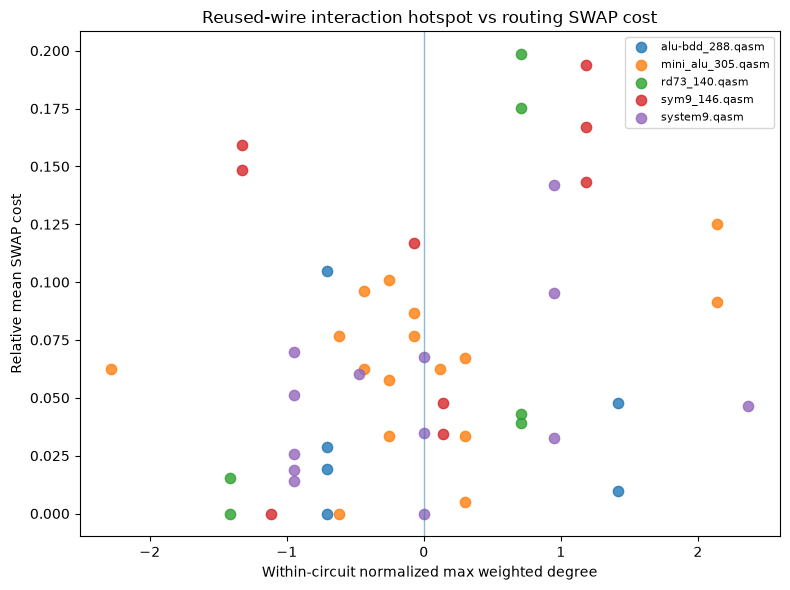

In [112]:
# ============================================================
# Figure 1
# Reused-wire hotspot vs relative SWAP cost
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 6)
)


for circuit_name, group in (
    df_final.groupby("circuit")
):

    ax.scatter(
        group[
            "max_weighted_degree_z"
        ],

        group[
            "within_circuit_relative_swaps"
        ],

        label=circuit_name,
        s=55,
        alpha=0.8,
    )


ax.axvline(
    0,
    linewidth=1,
    alpha=0.5
)


ax.set_xlabel(
    "Within-circuit normalized max weighted degree"
)

ax.set_ylabel(
    "Relative mean SWAP cost"
)

ax.set_title(
    "Reused-wire interaction hotspot vs routing SWAP cost"
)

ax.legend(
    fontsize=8
)

fig.tight_layout()


fig.savefig(
    OUTPUT_DIR /
    "experiment2_hotspot_vs_swap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

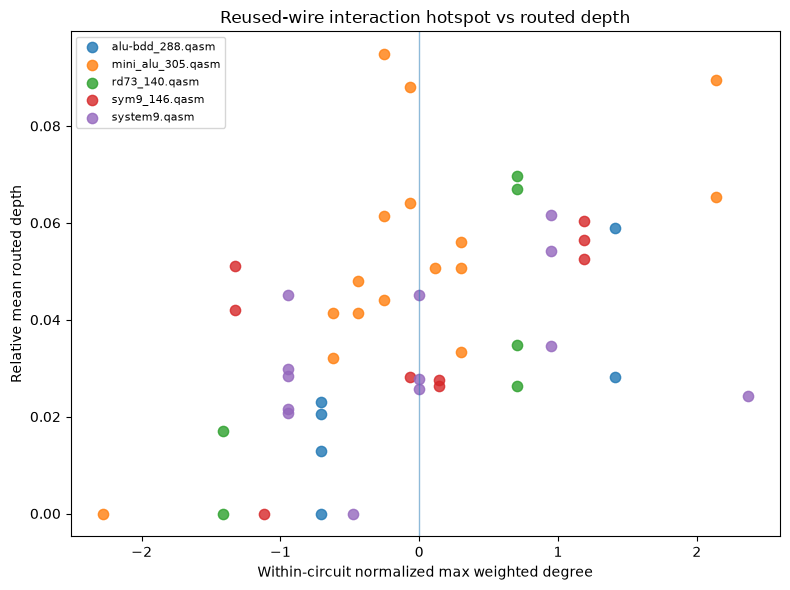

In [113]:
# ============================================================
# Figure 2
# Reused-wire hotspot vs relative routed depth
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 6)
)


for circuit_name, group in (
    df_final.groupby("circuit")
):

    ax.scatter(
        group[
            "max_weighted_degree_z"
        ],

        group[
            "within_circuit_relative_routed_depth"
        ],

        label=circuit_name,
        s=55,
        alpha=0.8,
    )


ax.axvline(
    0,
    linewidth=1,
    alpha=0.5
)


ax.set_xlabel(
    "Within-circuit normalized max weighted degree"
)

ax.set_ylabel(
    "Relative mean routed depth"
)

ax.set_title(
    "Reused-wire interaction hotspot vs routed depth"
)

ax.legend(
    fontsize=8
)

fig.tight_layout()


fig.savefig(
    OUTPUT_DIR /
    "experiment2_hotspot_vs_routed_depth.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

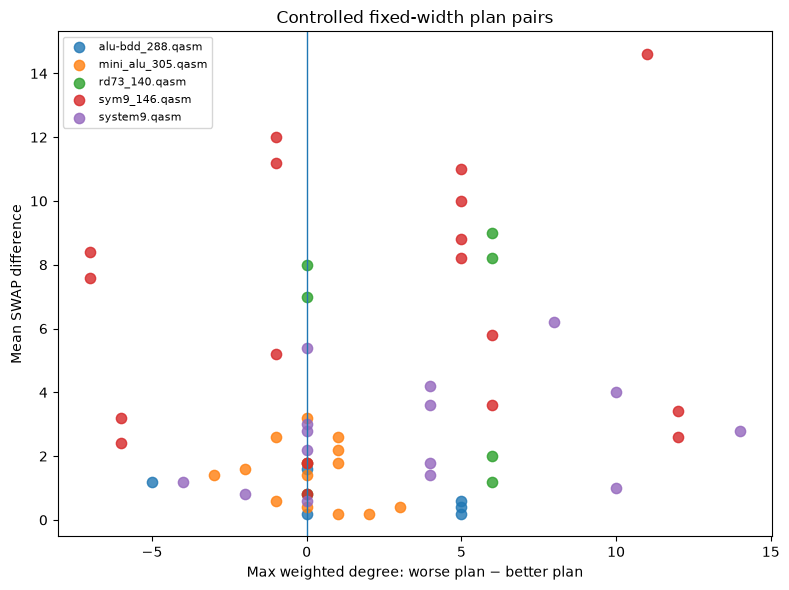

In [114]:
# ============================================================
# Figure 3
# Controlled pairwise hotspot difference vs SWAP difference
# ============================================================

plot_pairs = (
    controlled_final.copy()
)


# Orient every pair:
# x > 0 means the worse-SWAP plan
# has a larger max_weighted_degree.

swap_sign = np.sign(
    plot_pairs[
        "delta_swaps"
    ]
)


plot_pairs[
    "worse_minus_better_swaps"
] = np.abs(
    plot_pairs[
        "delta_swaps"
    ]
)


plot_pairs[
    "worse_minus_better_max_weighted_degree"
] = (
    swap_sign
    *
    plot_pairs[
        "delta_max_weighted_degree"
    ]
)


fig, ax = plt.subplots(
    figsize=(8, 6)
)


for circuit_name, group in (
    plot_pairs.groupby(
        "circuit"
    )
):

    ax.scatter(
        group[
            "worse_minus_better_max_weighted_degree"
        ],

        group[
            "worse_minus_better_swaps"
        ],

        label=circuit_name,
        s=55,
        alpha=0.8,
    )


ax.axvline(
    0,
    linewidth=1
)


ax.set_xlabel(
    "Max weighted degree: worse plan − better plan"
)

ax.set_ylabel(
    "Mean SWAP difference"
)

ax.set_title(
    "Controlled fixed-width plan pairs"
)

ax.legend(
    fontsize=8
)

fig.tight_layout()


fig.savefig(
    OUTPUT_DIR /
    "experiment2_controlled_pair_hotspot_vs_swap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [115]:
# ============================================================
# Experiment 2 — Finalization Step 7
# Strongest depth-matched forensic pair per circuit
# ============================================================

forensic_rows = []


for circuit_name, group in (
    pairwise_final.groupby("circuit")
):

    candidates = group[
        group[
            "depth_matched_5pct"
        ]
    ].copy()


    if len(candidates) == 0:
        continue


    candidates[
        "absolute_swap_gap"
    ] = abs(
        candidates[
            "delta_swaps"
        ]
    )


    strongest = (
        candidates
        .sort_values(
            "absolute_swap_gap",
            ascending=False
        )
        .iloc[0]
    )


    forensic_rows.append(
        strongest
    )


forensic_pairs_final = (
    pd.DataFrame(
        forensic_rows
    )
)


display(
    forensic_pairs_final[
        [
            "circuit",
            "plan_a",
            "plan_b",
            "logical_depth_a",
            "logical_depth_b",
            "swaps_a",
            "swaps_b",
            "max_weighted_degree_a",
            "max_weighted_degree_b",
            "weighted_degree_cv_a",
            "weighted_degree_cv_b",
        ]
    ]
)

,circuit,plan_a,plan_b,logical_depth_a,logical_depth_b,swaps_a,swaps_b,max_weighted_degree_a,max_weighted_degree_b,weighted_degree_cv_a,weighted_degree_cv_b
5,alu-bdd_288.qasm,P1,P2,50.0,52.0,23.2,21.0,20.0,20.0,0.192483,0.326040
113,mini_alu_305.qasm,P2,P9,94.0,98.0,41.6,46.8,39.0,54.0,0.309789,0.508322
144,rd73_140.qasm,P2,P3,142.0,142.0,61.6,51.4,56.0,50.0,0.329458,0.175728
161,sym9_146.qasm,P1,P5,199.0,197.0,75.4,90.0,71.0,82.0,0.198837,0.275788
261,system9.qasm,P7,P8,177.0,177.0,86.0,98.2,67.0,71.0,0.471051,0.442443


In [116]:
# ============================================================
# Experiment 2 — Finalization Step 8
# Save ALL final outputs
# ============================================================


# ------------------------------------------------------------
# 1. Boundary-level raw diagnostic data
# ------------------------------------------------------------

boundary_features_final.to_csv(
    OUTPUT_DIR /
    "experiment2_boundary_features.csv",
    index=False
)


# ------------------------------------------------------------
# 2. Plan-level feature table
# ------------------------------------------------------------

df_final.to_csv(
    OUTPUT_DIR /
    "experiment2_plan_features.csv",
    index=False
)


# ------------------------------------------------------------
# 3. All same-width plan pairs
# ------------------------------------------------------------

pairwise_final.to_csv(
    OUTPUT_DIR /
    "experiment2_pairwise.csv",
    index=False
)


# ------------------------------------------------------------
# 4. Strict controlled pair subset
# ------------------------------------------------------------

controlled_final.to_csv(
    OUTPUT_DIR /
    "experiment2_controlled_pairs.csv",
    index=False
)


# ------------------------------------------------------------
# 5. Main mechanism evidence
# ------------------------------------------------------------

final_mechanism_summary.to_csv(
    OUTPUT_DIR /
    "experiment2_mechanism_summary.csv",
    index=False
)


# ------------------------------------------------------------
# 6. Strong forensic pair per benchmark
# ------------------------------------------------------------

forensic_pairs_final.to_csv(
    OUTPUT_DIR /
    "experiment2_forensic_pairs.csv",
    index=False
)


# ------------------------------------------------------------
# 7. Full statistical table from previous analysis
# ------------------------------------------------------------

final_statistical_summary.to_csv(
    OUTPUT_DIR /
    "experiment2_statistical_summary.csv",
    index=False
)


print(
    "Saved all Experiment 2 outputs to:"
)

print(
    OUTPUT_DIR.resolve()
)

Saved all Experiment 2 outputs to:
C:\Users\ASUS\Documents\Quantum computing\Qiskit\GidNET-Qubit-Reuse-Algorithm\experiment2_results


In [117]:
# ============================================================
# Experiment 2 — FINAL INTEGRITY CHECK
# ============================================================

required_files = [

    "experiment2_boundary_features.csv",

    "experiment2_plan_features.csv",

    "experiment2_pairwise.csv",

    "experiment2_controlled_pairs.csv",

    "experiment2_mechanism_summary.csv",

    "experiment2_forensic_pairs.csv",

    "experiment2_statistical_summary.csv",

    "experiment2_hotspot_vs_swap.png",

    "experiment2_hotspot_vs_routed_depth.png",

    "experiment2_controlled_pair_hotspot_vs_swap.png",
]


print("=" * 70)
print("EXPERIMENT 2 — FINAL CHECK")
print("=" * 70)


print(
    "\nNumber of circuits:",
    df_final[
        "circuit"
    ].nunique()
)


print(
    "Number of unique plans:",
    df_final[
        [
            "circuit",
            "plan_id"
        ]
    ]
    .drop_duplicates()
    .shape[0]
)


print(
    "Strict controlled pairs:",
    len(
        controlled_final
    )
)


print(
    "Boundary observations:",
    len(
        boundary_features_final
    )
)


print(
    "\nPrimary mechanism evidence:"
)

display(
    final_mechanism_summary
)


print(
    "\nGenerated files:"
)


for filename in required_files:

    path = (
        OUTPUT_DIR
        /
        filename
    )

    print(
        f"{'OK' if path.exists() else 'MISSING':8s}",
        filename
    )

EXPERIMENT 2 — FINAL CHECK

Number of circuits: 5
Number of unique plans: 50
Strict controlled pairs: 61
Boundary observations: 234

Primary mechanism evidence:


,feature,n_informative_pairs,total_controlled_pairs,coverage,ordering_accuracy,partial_r_swap,adjusted_p_swap,partial_r_routed_depth,adjusted_p_routed_depth,interpretation
0,max_weighted_degree,44,61,0.721311,0.681818,0.471481,0.011599,0.513915,0.003800,Maximum total two-qubit interaction load incid...
1,weighted_degree_cv,60,61,0.983607,0.616667,0.475191,0.010299,0.487237,0.007399,Global imbalance of two-qubit interaction load...



Generated files:
OK       experiment2_boundary_features.csv
OK       experiment2_plan_features.csv
OK       experiment2_pairwise.csv
OK       experiment2_controlled_pairs.csv
OK       experiment2_mechanism_summary.csv
OK       experiment2_forensic_pairs.csv
OK       experiment2_statistical_summary.csv
OK       experiment2_hotspot_vs_swap.png
OK       experiment2_hotspot_vs_routed_depth.png
OK       experiment2_controlled_pair_hotspot_vs_swap.png







**Experiment 2 conclusion.**

Width-equivalent GidNET reuse plans differ not only in logical structure but also in how two-qubit interaction traffic is distributed across reused wires. The initial local reuse-boundary incompatibility hypothesis based on tail/head interaction overlap did not consistently explain physical-cost variation. In contrast, quotient-graph load metrics showed a repeated association with routing cost. In particular, plans with a larger maximum weighted degree and greater weighted-degree imbalance tended to exhibit higher SWAP counts and routed depths. These relationships remained after controlling for logical depth, quotient edge count, and maximum unweighted degree, and remained stable under leave-one-circuit-out analysis. The results establish an interaction-load hotspot as a candidate structural mechanism, but do not establish causality. Experiment 3 will test whether actively reducing this hotspot can improve physical routing cost while preserving reuse width.